# 2. WEEKLY MOMENTUM (ETHUSD) - IN-SAMPLE PARAMETER STABILITY & PLATEAU CHECK

In-sample sensitivity analysis of the **Weekly Momentum** rules on hourly Axi ETHUSD CFD bars (UTC), same flow as notebook 02 of Monday Effect / RSI2 / Gotobi, adapted to a weekly time-series momentum rule with real spread, swap and overlapping holds.

### STRICT METHODOLOGICAL CONSTRAINT
> **IN-SAMPLE DATA ONLY**: only trades that are closed before `split.oos_start` (2024-01-01) are used. Out-of-sample data is not touched here; it belongs to notebook 03.

### OBJECTIVES
1. **Plateau vs. Cliff**: the configured point (`lookback_days`, `hold_days`) must sit on a stable region of the grid `grid.lookback_days_values x grid.hold_days_values`, not on an isolated peak.
2. **Anti-Cliff**: one step away must not drop the Profit Factor by more than the gate limit.

### EDGE-SPECIFIC CHECKS
3. **Cost / swap stress**: the swap (-20 % annual on longs) is a large structural cost; does the plateau survive spread x2 and swap x2?
4. **Dose-response**: a stronger past momentum should be followed by a better next week.
5. **Entry-timing robustness**: the rule should not live only at Monday 00:00 server (hour and weekday sweep). A pass only rules out a single-slot artefact; it is **not** evidence for the signal.
6. **Signal ablation by year**: what the momentum filter adds over the naked position (ETH drift) and whether it is carried by a single year (2020-21 in the research).
7. **Evidence bar**: the in-sample t against a Bonferroni threshold for the number of hypotheses declared in the YAML (`evidence_thresholds.hypotheses_tested`).
8. **Declared checks**: every gate goes into one `Checks` registry (section 9) that is saved in `02_plateau.json`, so notebook 03 can list the inherited FAILs next to its own verdict.

### NOTES THAT CHANGE HOW THE GRID IS READ
- **Grid size comes from the YAML** (lookbacks x holds, currently 27 x 30 = 810 cells). The notebook still prints `edge_of_grid`: a truncated 3x3 neighbourhood is weaker evidence than an interior point.
- **Holds longer than 7 days overlap** (one entry per week, each held `hold_days`): the plain t-stat of the mean trade is overstated, so every t in this notebook is **Newey-West** (lag = round(hold/7) - 1). Use the same adjusted t (`tstat_hac`) in notebooks 01 and 03.
- All cells use **one common window** (first date where every lookback has a valid signal) so they are comparable.
- This variant (long only) was picked after seeing v1's results: its plateau is evidence of stability, not of independent confirmation.
- The grid **without 2020-21** is a declared check, no longer a footnote: it is the most important fragility of the strategy.

### STRATEGY PARAMETERS

In [75]:
VARIANT = "v2_ethusd_long"   # base variants: "v1_ethusd" (both legs) | "v2_ethusd_long" (long only)
HARD_LIMIT = 0.09
BULL_YEARS = (2020, 2021)    # fixed a priori in notebook 01, section 1.1 (research carried by 2020-21)

# ---- thresholds of the declared checks (registry in section 9) ----
P_DOSE_MAX     = 0.05   # dose-response: Spearman p (past return vs move over the hold) must be <= this
K_HYP_FALLBACK = 2      # Bonferroni k, used only if the YAML has no evidence_thresholds.hypotheses_tested (v1 + long only)

## 1. IMPORTS AND CONFIG

In [76]:
import sys, importlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

def find_upwards(name, start=None, must_be_dir=True):
    here = (start or Path.cwd()).resolve()
    for base in (here, *here.parents):
        target = base / name
        if target.is_dir() if must_be_dir else target.exists():
            return base
    raise FileNotFoundError(f"Could not find '{name}' walking up from {here}")

EDGE_DIR   = find_upwards('variants')
utils_path = str(find_upwards('utils') / 'utils')
for p in (utils_path, str(EDGE_DIR)):
    if p not in sys.path:
        sys.path.insert(0, p)

from robustness import grid_search, plateau_check, plot_grid, profit_factor
from validation_gate import DEFAULTS as GATE
import weekly_momentum_engine as eng
import variant_config
from variant_config import load_variant, save_json

importlib.reload(eng)
variant_config.EDGE_DIR = EDGE_DIR
assert (EDGE_DIR / "variants").is_dir()

cfg        = load_variant(VARIANT)
eng.set_engine_defaults(**cfg.get("engine_defaults", {}))
RUN_DIR    = cfg["run_dir"]
TICKER     = cfg["instrument"]["ticker"]
DATA_START = cfg["instrument"]["start"]
OOS_START  = cfg["oos_start_ts"]
P          = cfg["params"]
LOOKBACK, HOLD, ENTRY_DOW, ENTRY_HOUR = int(P["lookback_days"]), int(P["hold_days"]), P["entry_dow"], P["entry_hour"]
DIRECTION, COST_MODE, COST_BPS = P["direction"], P["cost_mode"], P["cost_bps_per_side"]
LOOKBACKS = [int(x) for x in cfg["grid"]["lookback_days_values"]]
HOLDS     = [int(x) for x in cfg["grid"]["hold_days_values"]]
CHOSEN    = (LOOKBACK, HOLD)
SIZE_FRAC = eng.ENGINE_DEFAULTS["size_fraction"]
SWAP_L0, SWAP_S0 = eng.ENGINE_DEFAULTS["swap_long_pct_annual"], eng.ENGINE_DEFAULTS["swap_short_pct_annual"]
PF_MIN, N_MIN, MAX_DROP = GATE["plateau_pf_min"], GATE["plateau_n_min"], GATE["plateau_max_drop"]

# Rules that never change in the sweeps (lookback_days / hold_days are swept)
RULES_KW = dict(entry_dow=ENTRY_DOW, entry_hour=ENTRY_HOUR, direction=DIRECTION, cost_mode=COST_MODE, cost_bps_per_side=COST_BPS)
NAKED_DIR = "short_only" if DIRECTION == "short_only" else "long_only"

BG, PANEL, GRIDC, TXT, SUB, GREEN, RED, ORANGE = "#15171c", "#1b1e26", "#2a2d37", "#e8e9ec", "#9aa0ab", "#34d399", "#f0555a", "#f5a524"
def dark_ax(ax):
    ax.set_facecolor(PANEL); ax.grid(color=GRIDC, alpha=0.8); ax.tick_params(colors=SUB)
    for s in ax.spines.values():
        s.set_visible(False)

# ---- plot style shared by every figure (same look as the Gotobi notebook) ----
BLUE, GOLDC = "#5b8def", "#f5c542"
plt.rcParams.update({"figure.facecolor": BG, "savefig.facecolor": BG, "axes.facecolor": PANEL, "text.color": TXT,
                     "axes.labelcolor": SUB, "xtick.color": SUB, "ytick.color": SUB, "axes.edgecolor": GRIDC, "font.size": 9})

def set_title(ax, s):
    ax.set_title(s, color=TXT, fontweight="bold", loc="left", fontsize=10.5)

def legend(ax, loc="best"):
    ax.legend(frameon=False, labelcolor=SUB, fontsize=8, loc=loc)

def subplots(nrows=1, ncols=1, figsize=(10, 4), grid=True, **kw):
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize, facecolor=BG, **kw)
    for ax in np.atleast_1d(axes).ravel():
        dark_ax(ax)
        if not grid:
            ax.grid(False)
    return fig, axes

def heatmap(ax, g, title, center=None, vmin=None, vmax=None, fmt="{:.2f}", mark=None, annotate=True, fs=5.5, cmap="RdYlGn", cbar=True):
    """Annotated heatmap of a (lookback x hold) frame. Blue square = configured cell.
    center -> colour scale symmetric around it (e.g. PF gate); vmin/vmax -> fixed scale (shared between panels)."""
    v = g.to_numpy(float)
    fin = v[np.isfinite(v)]
    if vmin is None or vmax is None:
        if center is not None and len(fin):
            span = float(np.max(np.abs(fin - center))) or 1.0
            vmin, vmax = center - span, center + span
        elif len(fin):
            vmin, vmax = float(fin.min()), float(fin.max())
        else:
            vmin, vmax = 0.0, 1.0
    im = ax.imshow(v, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    ax.set_xticks(range(g.shape[1])); ax.set_xticklabels([str(c) for c in g.columns], color=SUB, fontsize=6.5)
    ax.set_yticks(range(g.shape[0])); ax.set_yticklabels([str(r) for r in g.index], color=SUB, fontsize=6.5)
    if annotate:
        for (r, c), val_ in np.ndenumerate(v):
            if np.isfinite(val_):
                rgb = im.cmap(im.norm(val_))[:3]
                ax.text(c, r, fmt.format(val_), ha="center", va="center", fontsize=fs,
                        color="#15171c" if (0.299 * rgb[0] + 0.587 * rgb[1] + 0.114 * rgb[2]) > 0.5 else TXT)
    if mark is not None:
        r, c = g.index.get_loc(mark[0]), g.columns.get_loc(mark[1])
        ax.add_patch(plt.Rectangle((c - 0.5, r - 0.5), 1, 1, fill=False, ec=BLUE, lw=2.5))
    ax.set_xlabel("hold (days)", color=SUB); ax.set_ylabel("lookback (days)", color=SUB)
    set_title(ax, title)
    if cbar:
        cb = ax.figure.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
        cb.ax.tick_params(colors=SUB, labelsize=7); cb.outline.set_visible(False)
    return im

class Checks:
    """PASS / FAIL / INFO registry (INFO = reported, not a gate). Saved to 02_plateau.json for notebook 03."""
    def __init__(self):
        self.items = []
    def __call__(self, section, name, ok, detail=""):
        status = "INFO" if ok is None else ("PASS" if bool(ok) else "FAIL")
        self.items.append(dict(section=section, name=name, status=status, detail=str(detail)))
        print(f"   [{status}] {name}" + (f"  ->  {detail}" if detail != "" else ""))
        return status
    def frame(self):
        return pd.DataFrame(self.items)
    def counts(self):
        st = [i["status"] for i in self.items]
        return {k: st.count(k) for k in ("PASS", "FAIL", "INFO")}

C = Checks()

def hypothesis_threshold(k, alpha=0.05):
    """One-sided Bonferroni threshold for a t-stat when k hypotheses were looked at (normal approximation)."""
    return float(stats.norm.isf(alpha / max(int(k), 1)))

def tstat(x):
    x = np.asarray(x, float); x = x[~np.isnan(x)]
    return float(x.mean() / (x.std(ddof=1) / np.sqrt(len(x)))) if len(x) > 2 and x.std(ddof=1) > 0 else np.nan

def tstat_hac(x, lags):
    """t-stat of the mean with Newey-West (Bartlett) variance; lags = 0 is the plain t-stat."""
    x = np.asarray(x, float); x = x[~np.isnan(x)]
    if lags <= 0 or len(x) < 5:
        return tstat(x)
    e, n = x - x.mean(), len(x)
    s = float(e @ e) / n
    for k in range(1, min(lags, n - 1) + 1):
        s += 2 * (1 - k / (lags + 1)) * float(e[k:] @ e[:-k]) / n
    return float(x.mean() / np.sqrt(max(s, 1e-18) / n))

def summarize(t, hold=None):
    """PF / mean net % / t (overlap-adjusted) / win rate of a trades frame (100% capital, net of spread and swap)."""
    if len(t) == 0:
        return dict(n=0, pf=np.nan, mean=np.nan, t=np.nan, win=np.nan)
    lags = max(int(round((hold or HOLD) / 7)) - 1, 0)
    return dict(n=len(t), pf=profit_factor(t["pnl"]), mean=float(t["pnl"].mean()),
                t=tstat_hac(t["pnl"], lags), win=float((t["pnl"] > 0).mean() * 100))

print(f"Loaded weekly_momentum_engine from: {eng.__file__}")
print(f"Variant: {cfg['id']} | {TICKER} | candidate lookback {LOOKBACK} d, hold {HOLD} d | {DIRECTION} | cost: {COST_MODE}")
print(f"Grid: {len(LOOKBACKS)} lookbacks x {len(HOLDS)} holds = {len(LOOKBACKS) * len(HOLDS)} cells")
print(f"Gate criteria (validation_gate.DEFAULTS): PF >= {PF_MIN}, N >= {N_MIN}, max drop {MAX_DROP}%")
print(f"Run folder: {RUN_DIR}")

Loaded weekly_momentum_engine from: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/ETHUSD_Weekly_Momentum/weekly_momentum_engine.py
Variant: WEEKLY_MOM.ethusd.cfd.v1 | ethusd | candidate lookback 31 d, hold 11 d | long_only | cost: spread
Grid: 27 lookbacks x 30 holds = 810 cells
Gate criteria (validation_gate.DEFAULTS): PF >= 1.3, N >= 30, max drop 30%
Run folder: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/ETHUSD_Weekly_Momentum/runs/v2_ethusd_long


## 2. IN-SAMPLE DATA SETUP

`prepare()` runs once per lookback on the full history (the signal warm-up is kept). Every grid cell is then cut to the **same** window: from the first entry where *all* lookbacks have a valid signal, up to `oos_start`. A trade is in-sample only if it **closes** before `oos_start` (stricter than notebook 01, which splits by entry date: the week that opens right at the cut would use OOS prices for its exit).

In [77]:
df_raw = eng.load_data(TICKER, start=DATA_START)
step_h = df_raw.index.to_series().diff().dt.total_seconds().div(3600).dropna()
print(f"{len(df_raw):,} hourly bars | {df_raw.index[0]} -> {df_raw.index[-1]} | steps != 1 h: {int((step_h != 1).sum())}")
if (step_h.iloc[:48] > 1).any():
    print("WARNING: the first candles are not hourly (daily head / weekend gaps). Weeks touching them are discarded by the engine; "
          "check instrument.start in the YAML.")

preps = {L: eng.prepare(df_raw, lookback_days=L, entry_dow=ENTRY_DOW, entry_hour=ENTRY_HOUR) for L in LOOKBACKS}
first_valid = {L: d.index[d["mom_ret"].notna()][0] for L, d in preps.items()}
COMMON_START = max(first_valid.values())
IS_END = OOS_START
print("First valid entry by lookback:", {L: f"{t:%Y-%m-%d}" for L, t in first_valid.items()})

def run_cell(L, H, d=None, **kw):
    """In-sample trades of one cell: one engine run on the full df, then cut to [COMMON_START, entry..exit <= OOS_START]."""
    d = preps[L] if d is None else d
    t = eng.run_weekly_backtest(d, lookback_days=L, hold_days=H, **{**RULES_KW, **kw})
    et, xt = pd.to_datetime(t["entry_time"]), pd.to_datetime(t["exit_time"])
    return t[(et >= COMMON_START) & (xt <= IS_END)].reset_index(drop=True)

t_cfg = run_cell(LOOKBACK, HOLD)
t_cfg_entry_rule = eng.split_trades(eng.run_weekly_backtest(preps[LOOKBACK], lookback_days=LOOKBACK, hold_days=HOLD, **RULES_KW), OOS_START)[0]
t_cfg_entry_rule = t_cfg_entry_rule[pd.to_datetime(t_cfg_entry_rule["entry_time"]) >= COMMON_START]

print("=" * 70)
print("IN-SAMPLE WINDOW (ONE WINDOW FOR EVERY GRID CELL)")
print("=" * 70)
print(f"First entry: {COMMON_START:%Y-%m-%d} | trades close before: {IS_END:%Y-%m-%d} | {(IS_END - COMMON_START).days / 365.25:.1f} years")
print(f"Configured cell {CHOSEN}: {len(t_cfg)} trades (splitting by entry date like notebook 01 would give {len(t_cfg_entry_rule)})")
print(f"Spread not recorded (SPREAD = 0) filled with the annual median: {(df_raw['spread'] == 0).mean():.1%} of the candles")
print(f"OOS block (not used here) starts: {OOS_START:%Y-%m-%d}")

68,722 hourly bars | 2019-01-01 00:00:00 -> 2026-11-06 10:00:00 | steps != 1 h: 18
First valid entry by lookback: {7: '2019-01-13', 10: '2019-01-13', 13: '2019-01-20', 16: '2019-01-20', 19: '2019-01-20', 22: '2019-01-27', 25: '2019-01-27', 28: '2019-02-03', 31: '2019-02-03', 34: '2019-02-10', 37: '2019-02-10', 40: '2019-02-10', 43: '2019-02-17', 46: '2019-02-17', 49: '2019-02-24', 52: '2019-02-24', 55: '2019-03-03', 58: '2019-03-03', 61: '2019-03-03', 64: '2019-03-10', 67: '2019-03-10', 70: '2019-03-17', 73: '2019-03-17', 76: '2019-03-24', 79: '2019-03-24', 82: '2019-03-24', 85: '2019-03-31'}
IN-SAMPLE WINDOW (ONE WINDOW FOR EVERY GRID CELL)
First entry: 2019-03-31 | trades close before: 2024-01-01 | 4.8 years
Configured cell (31, 11): 142 trades (splitting by entry date like notebook 01 would give 144)
Spread not recorded (SPREAD = 0) filled with the annual median: 6.8% of the candles
OOS block (not used here) starts: 2024-01-01


## 3. 2D PARAMETER GRID (LOOKBACK x HOLD)

Each cell runs the frozen rules with only `lookback_days` and `hold_days` changed. PF is the plateau metric; mean net return, the overlap-adjusted t-stat and the drawdown at the robot sizing (`size_fraction`, intra-candle, in-sample trades only) are added. With `hold > 7` consecutive positions overlap, so the drawdown at the same fraction is not comparable one-to-one with `hold = 7`. The grids are drawn as annotated heatmaps (blue square = configured cell).

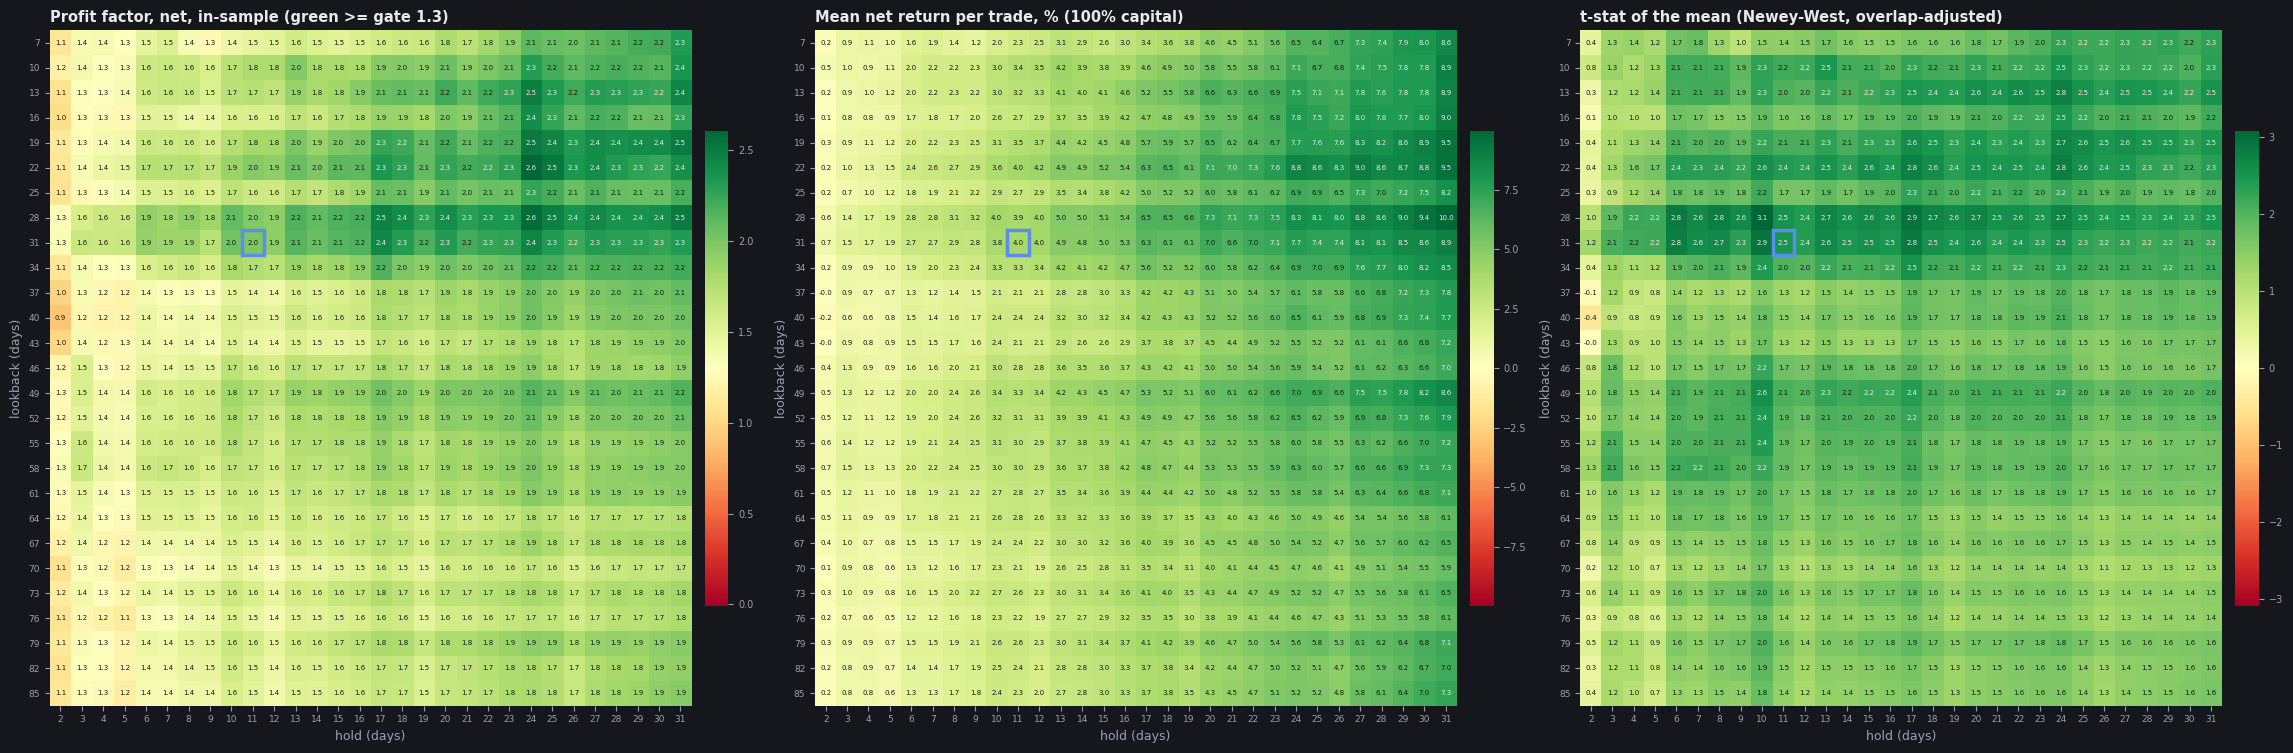

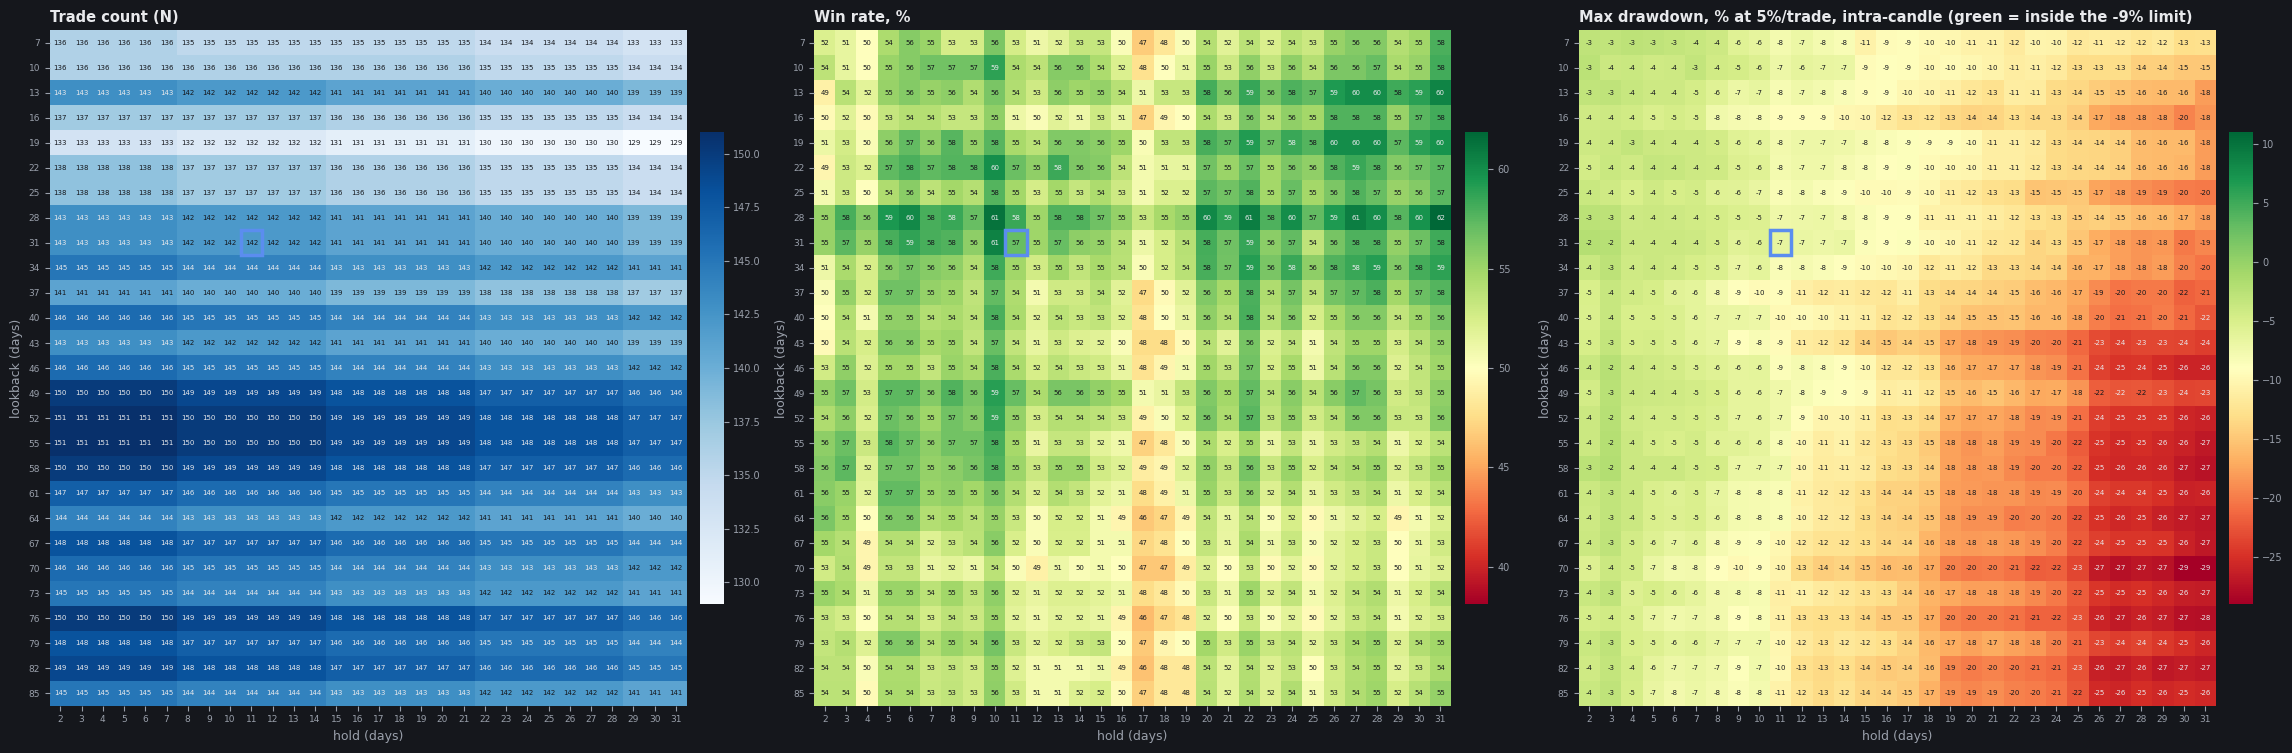

Configured cell (31, 11): PF 1.989 | N 142 | mean net +3.968% | t 2.51 | win 57.0% | MaxDD -6.6% (hard limit -9%)


In [78]:
TR = {}
def evaluate(L, H):
    t = run_cell(L, H); TR[(L, H)] = t
    return (profit_factor(t["pnl"]) if len(t) else 0.0, len(t))

pf_grid, n_grid = grid_search(evaluate, LOOKBACKS, HOLDS)
mk = lambda f: pd.DataFrame({H: {L: f(L, H) for L in LOOKBACKS} for H in HOLDS})
mean_grid = mk(lambda L, H: summarize(TR[(L, H)], H)["mean"])
t_grid    = mk(lambda L, H: summarize(TR[(L, H)], H)["t"])
win_grid  = mk(lambda L, H: summarize(TR[(L, H)], H)["win"])
def _dd(L, H):
    t = TR[(L, H)]
    return 100 * eng.hard_limit_report_intrabar(preps[L], t, HARD_LIMIT, "fraction")["max_dd"] if len(t) else np.nan
dd_grid = mk(_dd)

# ---- heatmaps (blue square = configured cell); the full 27 x 30 tables were truncated in the output anyway ----
fig, axes = subplots(1, 3, figsize=(23, 7.6), grid=False)
heatmap(axes[0], pf_grid, f"Profit factor, net, in-sample (green >= gate {PF_MIN})", center=PF_MIN, fmt="{:.1f}", mark=CHOSEN, fs=5)
heatmap(axes[1], mean_grid, "Mean net return per trade, % (100% capital)", center=0.0, fmt="{:.1f}", mark=CHOSEN, fs=5)
heatmap(axes[2], t_grid, "t-stat of the mean (Newey-West, overlap-adjusted)", center=0.0, fmt="{:.1f}", mark=CHOSEN, fs=5)
plt.tight_layout(); plt.show()

fig, axes = subplots(1, 3, figsize=(23, 7.6), grid=False)
heatmap(axes[0], n_grid.astype(float), "Trade count (N)", fmt="{:.0f}", mark=CHOSEN, fs=5, cmap="Blues")
heatmap(axes[1], win_grid, "Win rate, %", center=50.0, fmt="{:.0f}", mark=CHOSEN, fs=5)
heatmap(axes[2], dd_grid, f"Max drawdown, % at {SIZE_FRAC:.0%}/trade, intra-candle (green = inside the -{HARD_LIMIT:.0%} limit)",
        center=-100 * HARD_LIMIT, fmt="{:.0f}", mark=CHOSEN, fs=5)
plt.tight_layout(); plt.show()

print(f"Configured cell {CHOSEN}: PF {pf_grid.loc[LOOKBACK, HOLD]:.3f} | N {int(n_grid.loc[LOOKBACK, HOLD])} | mean net {mean_grid.loc[LOOKBACK, HOLD]:+.3f}% | "
      f"t {t_grid.loc[LOOKBACK, HOLD]:.2f} | win {win_grid.loc[LOOKBACK, HOLD]:.1f}% | MaxDD {dd_grid.loc[LOOKBACK, HOLD]:.1f}% (hard limit -{HARD_LIMIT:.0%})")

## 3.5 COST AND SWAP STRESS

The swap on longs (-20 % annual, about 0.38 % per week) is of the same order as the mean gross move, so the grid is repeated with spread x2, swap x2 and both. Each scenario also reports how many cells would pass the plateau gate if they were the configured one. The last figure is static (one panel per scenario) instead of the interactive 3D surface.

Configured cell lookback 31, hold 11 by scenario (grid = 810 cells):


,PF,N,Mean net %,t,MaxDD %,Worst nbr drop %,Plateau (configured),Cells passing,Cells PF >= gate
Scenario,,,,,,,,,
Base,1.989,142.0,3.968,2.505,-6.554,13.704,PASS,690,757
Spread x2,1.934,142.0,3.798,2.405,-6.655,13.480,PASS,656,725
Swap x2,1.786,142.0,3.350,2.121,-6.790,15.322,PASS,544,674
Spread x2 + Swap x2,1.736,142.0,3.181,2.021,-6.890,15.085,PASS,489,640


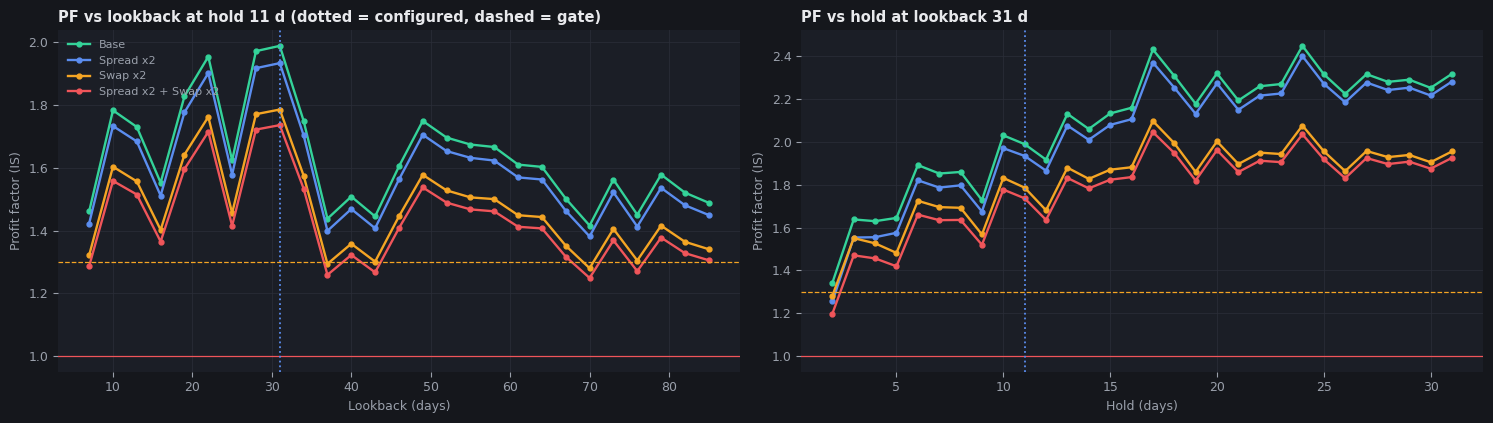

In [79]:
SCEN = [("Base", 1.0, 1.0), ("Spread x2", 2.0, 1.0), ("Swap x2", 1.0, 2.0), ("Spread x2 + Swap x2", 2.0, 2.0)]

def scenario_grids(sp_k, sw_k):
    eng.set_engine_defaults(swap_long_pct_annual=SWAP_L0 * sw_k, swap_short_pct_annual=SWAP_S0 * sw_k)
    try:
        dsc = {}
        for L in LOOKBACKS:
            d = preps[L].copy(); d["spread_px"] = d["spread_px"] * sp_k; dsc[L] = d
        pf, n, mean, tt, dd = (pd.DataFrame(index=LOOKBACKS, columns=HOLDS, dtype=float) for _ in range(5))
        for L in LOOKBACKS:
            for H in HOLDS:
                t = run_cell(L, H, d=dsc[L]); s = summarize(t, H)
                n.loc[L, H], pf.loc[L, H], mean.loc[L, H], tt.loc[L, H] = s["n"], s["pf"], s["mean"], s["t"]
                dd.loc[L, H] = 100 * eng.hard_limit_report_intrabar(dsc[L], t, HARD_LIMIT, "fraction")["max_dd"] if len(t) else np.nan
        return dict(pf=pf.replace(np.inf, np.nan), n=n, mean=mean, t=tt, dd=dd)
    finally:
        eng.set_engine_defaults(swap_long_pct_annual=SWAP_L0, swap_short_pct_annual=SWAP_S0)

def plateau_of(pf, n, L, H):
    try:
        r = plateau_check(pf.fillna(0.0), n.fillna(0.0), (L, H), pf_min=PF_MIN, n_min=N_MIN, max_drop_pct=MAX_DROP)
        return bool(r["passed"]), float(r["worst_neighbor_drop_pct"])
    except Exception:
        return False, np.nan

SG, rows = {}, []
for name, a, b in SCEN:
    g = scenario_grids(a, b); SG[name] = g
    n_pass = sum(plateau_of(g["pf"], g["n"], L, H)[0] for L in LOOKBACKS for H in HOLDS if pd.notna(g["pf"].loc[L, H]))
    ok, drop = plateau_of(g["pf"], g["n"], LOOKBACK, HOLD)
    rows.append({"Scenario": name, "PF": g["pf"].loc[LOOKBACK, HOLD], "N": g["n"].loc[LOOKBACK, HOLD], "Mean net %": g["mean"].loc[LOOKBACK, HOLD],
                 "t": g["t"].loc[LOOKBACK, HOLD], "MaxDD %": g["dd"].loc[LOOKBACK, HOLD], "Worst nbr drop %": drop,
                 "Plateau (configured)": "PASS" if ok else "FAIL", "Cells passing": n_pass,
                 "Cells PF >= gate": int((g["pf"] >= PF_MIN).sum().sum())})
stress = pd.DataFrame(rows).set_index("Scenario")
print(f"Configured cell lookback {LOOKBACK}, hold {HOLD} by scenario (grid = {len(LOOKBACKS) * len(HOLDS)} cells):")
display(stress.round(3))

sc_col = {"Base": GREEN, "Spread x2": BLUE, "Swap x2": ORANGE, "Spread x2 + Swap x2": RED}
fig, (ax1, ax2) = subplots(1, 2, figsize=(15, 4.3))
for name, _, _ in SCEN:
    ax1.plot(LOOKBACKS, SG[name]["pf"][HOLD].to_numpy(float), marker="o", ms=3.5, lw=1.7, color=sc_col[name], label=name)
    ax2.plot(HOLDS, SG[name]["pf"].loc[LOOKBACK].to_numpy(float), marker="o", ms=3.5, lw=1.7, color=sc_col[name], label=name)
for ax, mark, xl in ((ax1, LOOKBACK, "Lookback (days)"), (ax2, HOLD, "Hold (days)")):
    ax.axhline(1.0, color=RED, lw=0.9); ax.axhline(PF_MIN, color=ORANGE, ls="--", lw=0.9)
    ax.axvline(mark, color=BLUE, ls=":", lw=1.3)
    ax.set_xlabel(xl, color=SUB); ax.set_ylabel("Profit factor (IS)", color=SUB)
legend(ax1, "upper left")
set_title(ax1, f"PF vs lookback at hold {HOLD} d (dotted = configured, dashed = gate)")
set_title(ax2, f"PF vs hold at lookback {LOOKBACK} d")
plt.tight_layout(); plt.show()

In [80]:
import plotly.graph_objects as go
from pathlib import Path

LIMIT_PCT = HARD_LIMIT * 100.0
keys = [s[0] for s in SCEN]
nL, nH = len(LOOKBACKS), len(HOLDS)
XP = list(range(nL)); XT = [str(L) for L in LOOKBACKS]
X, Y = np.meshgrid(XP, HOLDS)                     # arrays are (hold, lookback)
LL = np.tile(np.array(LOOKBACKS), (nH, 1))
ib, ih = LOOKBACKS.index(LOOKBACK), HOLDS.index(HOLD)

# ---- gold ring criteria (essentials of notebook 01 that can be evaluated in-sample) ----
T_MIN, N_TR_MIN = 2.0, 100
STRICT_YEARS = False          # True -> concentration gates (t w/o best year, profitable years) also filter the gold ring
T_NO_BEST, YEARS_POS = 1.5, 0.75
NEAR = 0.90                   # near miss: fails some active gate but every active gate is >= 90% of its threshold
FULL_YEARS = [y for y in range(COMMON_START.year, OOS_START.year) if pd.Timestamp(f"{y}-01-01") >= COMMON_START]

# concentration stats from the BASE trades (always computed: hover, table, closeness)
shp = (nL, nH)
EX_N, TNB, YPOS = np.zeros(shp, bool), np.full(shp, np.nan), np.full(shp, np.nan)
for a, L in enumerate(LOOKBACKS):
    for b, H in enumerate(HOLDS):
        t = TR[(L, H)]
        if len(t) == 0:
            continue
        yr = pd.to_datetime(t["entry_time"]).dt.year
        best = t.groupby(yr)["pnl"].mean().idxmax()
        TNB[a, b] = tstat_hac(t.loc[yr != best, "pnl"], max(int(round(H / 7)) - 1, 0))
        YPOS[a, b] = float((t.groupby(yr)["pnl_frac"].sum().reindex(FULL_YEARS, fill_value=0.0) > 0).mean())
        EX_N[a, b] = len(t) >= N_TR_MIN
with np.errstate(invalid="ignore"):
    EXTRA = EX_N & (((TNB >= T_NO_BEST) & (YPOS >= YEARS_POS)) if STRICT_YEARS else np.ones(shp, bool))

# ---- pass 1: plateau + gold per scenario ----
PAS, DROP, GOLD = {}, {}, {}
for key in keys:
    g = SG[key]; pf, n = g["pf"], g["n"]
    pas = np.zeros(pf.shape, bool); drop = np.full(pf.shape, np.nan)
    for a, L in enumerate(LOOKBACKS):
        for b, H in enumerate(HOLDS):
            if pd.notna(pf.loc[L, H]):
                pas[a, b], drop[a, b] = plateau_of(pf, n, L, H)
    PAS[key], DROP[key] = pas, drop
    with np.errstate(invalid="ignore"):
        GOLD[key] = (pas & pf.notna().to_numpy() & (g["t"].to_numpy(float) >= T_MIN)
                     & ((g["dd"].to_numpy(float) + LIMIT_PCT) > 0) & EXTRA)
GOLD_ALL = np.logical_and.reduce([GOLD[k] for k in keys])
CFG_GOLD = {k: bool(GOLD[k][ib, ih]) for k in keys}
CFG_GOLD_ALL = bool(GOLD_ALL[ib, ih])

# ---- closeness: ratio value/threshold per gate (>= 1 passes) ----
GATES = ["plateau", "t", "hard limit", "N", "t w/o best yr", "years +"]
ACTIVE = list(range(6)) if STRICT_YEARS else list(range(4))
RAT, CLOSE, BIND, NPASS = {}, {}, {}, {}
for key in keys:
    g = SG[key]; pf = g["pf"].to_numpy(float); nn = g["n"].to_numpy(float)
    tt = g["t"].to_numpy(float); dd = g["dd"].to_numpy(float)
    nb = np.full(pf.shape, np.nan)
    for a in range(nL):
        for b in range(nH):
            blk = pf[max(a - 1, 0):a + 2, max(b - 1, 0):b + 2]
            nb[a, b] = np.nanmin(blk) if np.isfinite(blk).any() else np.nan
    with np.errstate(invalid="ignore", divide="ignore"):
        rp = np.minimum(nb / PF_MIN, np.where(DROP[key] > 0, MAX_DROP / DROP[key], np.inf))
        rp = np.where(PAS[key], np.maximum(rp, 1.0), np.minimum(rp, 0.999))
        R = np.stack([rp, np.maximum(tt, 0) / T_MIN, np.where(dd < 0, LIMIT_PCT / np.abs(dd), np.inf),
                      nn / N_TR_MIN, np.maximum(TNB, 0) / T_NO_BEST, YPOS / YEARS_POS])
    R = np.nan_to_num(R, nan=0.0, posinf=10.0)
    RAT[key] = R
    CLOSE[key] = R[ACTIVE].min(axis=0)
    BIND[key] = np.array(GATES)[np.array(ACTIVE)[R[ACTIVE].argmin(axis=0)]]
    NPASS[key] = (R[ACTIVE] >= 1.0).sum(axis=0)

# ---- capital / fraction needed to fit the hard limit (Base, linear approximation) ----
CAP = float(globals().get("CAPITAL", 3000.0))
LAST_PX = float(df_raw["close"].iloc[-1])
MIN_CAP = eng.min_capital_for_target(LAST_PX, SIZE_FRAC)
CAP_OK = bool(CAP >= MIN_CAP)
dd_b = SG["Base"]["dd"].to_numpy(float)
with np.errstate(invalid="ignore", divide="ignore"):
    F_FIT = np.where(dd_b < 0, np.minimum(SIZE_FRAC * LIMIT_PCT / np.abs(dd_b), 1.0), np.nan)
CAPF = np.full(shp, np.nan)
for a in range(nL):
    for b in range(nH):
        if np.isfinite(F_FIT[a, b]) and F_FIT[a, b] > 0:
            CAPF[a, b] = eng.min_capital_for_target(LAST_PX, float(F_FIT[a, b]))

# 3x3 neighbourhood of the configured cell (orange rings, as in Monday Effect)
rr = range(max(ib - 1, 0), min(ib + 2, nL))
cc = range(max(ih - 1, 0), min(ih + 2, nH))

pf_all = [SG[k]["pf"].to_numpy(float) for k in keys]
z_floor = min(1.0, float(np.nanmin([np.nanmin(a) for a in pf_all]))) - 0.35
z_top   = float(np.nanmax([np.nanmax(a) for a in pf_all])) + 0.25
amax    = max(1.0, max(float(np.nanmax(np.abs(SG[k]["dd"].to_numpy(float) + LIMIT_PCT))) for k in keys))
colorscale   = [[0.00, "#b5452f"], [0.25, "#e8a46a"], [0.50, "#f4e79a"], [0.75, "#8fd19e"], [1.00, "#2f7d55"]]
margin_scale = [[0.00, "#b5452f"], [0.45, "#e8704f"], [0.50, "#f5a524"], [0.55, "#8fd19e"], [1.00, "#34d399"]]
GOLDC, ORANGEC, NEARC = "#f5c542", "#f5a524", "#38bdf8"

TPS = 9                                           # traces per scenario
fig, titles, summ, cfg_rat = go.Figure(), [], [], []
T = lambda m: m.to_numpy(float).T if hasattr(m, "to_numpy") else m.T
for i, key in enumerate(keys):
    g = SG[key]; pf, n, dd = g["pf"], g["n"], g["dd"]
    margin = dd + LIMIT_PCT
    pas, drop, gold = PAS[key], DROP[key], GOLD[key]
    has = pf.notna().to_numpy()
    near = (CLOSE[key] >= NEAR) & ~gold & has
    cd = np.dstack([T(n), T(dd), T(margin), T(g["mean"]), T(g["t"]), drop.T, TNB.T, YPOS.T,
                    CLOSE[key].T * 100, NPASS[key].T, F_FIT.T * 100, CAPF.T])
    Z, pasT, hasT, goldT, gallT, nearT = T(pf), pas.T, has.T, gold.T, GOLD_ALL.T, near.T
    verdict = np.char.add(np.where(pasT, "PLATEAU OK", "plateau FAIL"), np.char.add(" · binding: ", BIND[key].T))
    vis = (i == 0)

    # 1) PF surface
    fig.add_trace(go.Surface(x=XP, y=HOLDS, z=Z, customdata=cd, text=verdict, colorscale=colorscale, cmin=1.0, cmax=2.0,
        colorbar=dict(title=dict(text="PF (IS)", side="top"), len=0.38, y=0.78, x=1.0, thickness=12),
        hovertemplate=("Lookback idx %{x} · hold %{y} d<br>PF (IS) %{z:.2f}<br>Trades %{customdata[0]:.0f}"
                       "<br>Mean net %{customdata[3]:.2f}% · t %{customdata[4]:.2f}"
                       "<br>MaxDD %{customdata[1]:.1f}% · margin %{customdata[2]:+.1f} pp"
                       "<br>t w/o best year %{customdata[6]:.2f} · profitable years %{customdata[7]:.0%}"
                       f"<br>Closeness %{{customdata[8]:.0f}}% of threshold · gates passed %{{customdata[9]:.0f}}/{len(ACTIVE)}"
                       "<br>Max fraction for limit ~%{customdata[10]:.1f}% · capital for min lot ~%{customdata[11]:,.0f}"
                       "<br>%{text}<extra></extra>"), visible=vis))
    # 2) floor: margin to the hard limit
    fig.add_trace(go.Surface(x=XP, y=HOLDS, z=np.full(Z.shape, z_floor), surfacecolor=T(margin), customdata=cd,
        colorscale=margin_scale, cmin=-amax, cmax=amax, opacity=0.95, lighting=dict(ambient=1.0, diffuse=0.0, specular=0.0),
        colorbar=dict(title=dict(text=f"Margin vs -{LIMIT_PCT:.0f}% (pp)", side="top"), len=0.38, y=0.30, x=1.0, thickness=12),
        hovertemplate=("FLOOR · lookback idx %{x} · hold %{y} d<br>MaxDD %{customdata[1]:.1f}%"
                       "<br>margin %{customdata[2]:+.1f} pp<extra></extra>"), visible=vis))
    # 3-4) plateau markers
    for mask, name, color, symbol in ((pasT & hasT, "Plateau OK", "#34d399", "diamond"),
                                      (~pasT & hasT, "Plateau FAIL", "#f87171", "x")):
        fig.add_trace(go.Scatter3d(x=X[mask], y=Y[mask], z=Z[mask] + 0.03, mode="markers", name=name, text=LL[mask],
            marker=dict(size=4, color=color, symbol=symbol), hovertemplate=f"{name}<br>lookback %{{text}} d · hold %{{y}} d<extra></extra>",
            showlegend=True, legendgroup=name, visible=vis))
    # 5) gold ring (this scenario)
    fig.add_trace(go.Scatter3d(x=X[goldT], y=Y[goldT], z=Z[goldT] + 0.06, mode="markers", name="Gold (this scenario)", text=LL[goldT],
        marker=dict(size=10, color="rgba(0,0,0,0)", symbol="circle-open", line=dict(color=GOLDC, width=4)),
        hovertemplate="Gold (this scenario)<br>lookback %{text} d · hold %{y} d<extra></extra>",
        showlegend=True, legendgroup="gold", visible=vis))
    # 6) gold diamond: gold in ALL scenarios
    fig.add_trace(go.Scatter3d(x=X[gallT], y=Y[gallT], z=Z[gallT] + 0.10, mode="markers", name="Gold in ALL scenarios", text=LL[gallT],
        marker=dict(size=8, color=GOLDC, symbol="diamond", line=dict(color="white", width=1.5)),
        hovertemplate="Gold in ALL scenarios<br>lookback %{text} d · hold %{y} d<extra></extra>",
        showlegend=True, legendgroup="goldall", visible=vis))
    # 7) near miss: not gold, every active gate >= NEAR of its threshold
    fig.add_trace(go.Scatter3d(x=X[nearT], y=Y[nearT], z=Z[nearT] + 0.08, mode="markers", name=f"Near miss (all gates >= {NEAR:.0%})", text=LL[nearT],
        marker=dict(size=8, color="rgba(0,0,0,0)", symbol="diamond-open", line=dict(color=NEARC, width=3)),
        hovertemplate="Near miss<br>lookback %{text} d · hold %{y} d<extra></extra>",
        showlegend=True, legendgroup="near", visible=vis))
    # 8) orange rings: 3x3 neighbourhood of the configured cell
    fig.add_trace(go.Scatter3d(x=[XP[a] for a in rr for b in cc], y=[HOLDS[b] for a in rr for b in cc],
        z=[float(pf.iloc[a, b]) + 0.07 for a in rr for b in cc], mode="markers", name="3x3 neighbourhood of configured",
        marker=dict(size=8, color="rgba(0,0,0,0)", symbol="circle-open", line=dict(color=ORANGEC, width=3)),
        hoverinfo="skip", showlegend=True, legendgroup="nbh", visible=vis))
    # 9) configured cell
    c_ok, c_pf = bool(pas[ib, ih]), float(pf.loc[LOOKBACK, HOLD]); col = "#34d399" if c_ok else "#f87171"
    fig.add_trace(go.Scatter3d(x=[XP[ib]], y=[HOLD], z=[c_pf + 0.14], mode="markers+text", text=[f"configured {'✓' if c_ok else '✗'}"],
        textposition="top center", textfont=dict(color=col, size=12), marker=dict(size=7, color="white", line=dict(color=col, width=3)),
        showlegend=False, hovertemplate=f"Configured lookback {LOOKBACK}, hold {HOLD}<br>plateau: {'PASS' if c_ok else 'FAIL'}<extra></extra>", visible=vis))
    n_pass, n_gold, n_near = int((pas & has).sum()), int(gold.sum()), int(near.sum())
    titles.append(f"{cfg['id']} · {key} · plateau {n_pass}/{int(has.sum())} · gold {n_gold} · near {n_near} · gold in all {int(GOLD_ALL.sum())}")
    summ.append({"Scenario": key, "PF (IS)": round(c_pf, 3), "N": int(n.loc[LOOKBACK, HOLD]),
                 "Mean net %": round(float(g["mean"].loc[LOOKBACK, HOLD]), 3), "t": round(float(g["t"].loc[LOOKBACK, HOLD]), 2),
                 "MaxDD %": round(float(dd.loc[LOOKBACK, HOLD]), 2), "Margin pp": round(float(margin.loc[LOOKBACK, HOLD]), 2),
                 "t w/o best yr": round(float(TNB[ib, ih]), 2), "Yrs +": f"{YPOS[ib, ih]:.0%}",
                 "Closeness %": round(float(CLOSE[key][ib, ih]) * 100), "Binding": str(BIND[key][ib, ih]),
                 "Plateau": "PASS" if c_ok else "FAIL", "Cfg gold": "YES" if CFG_GOLD[key] else "NO",
                 "Cells gold": n_gold, "Cells near": n_near})
    cfg_rat.append({"Scenario": key, **{gname: round(float(RAT[key][k, ib, ih]) * 100) for k, gname in enumerate(GATES)}})

PAD = "\u00a0\u00a0"; buttons = []
for i, key in enumerate(keys):
    v = [False] * (TPS * len(keys))
    for j in range(TPS):
        v[TPS * i + j] = True
    buttons.append(dict(label=f"{PAD}{key}{PAD}", method="update", args=[{"visible": v}, {"title.text": titles[i]}]))

act = [GATES[k] for k in ACTIVE]
gold_txt = f"Gold ring = {' + '.join(act)} all >= threshold (plateau PF>={PF_MIN}, drop<={MAX_DROP}%; t>={T_MIN:g}; margin>0; N>={N_TR_MIN}"
gold_txt += f"; t w/o best yr>={T_NO_BEST:g}; years+>={YEARS_POS:.0%})" if STRICT_YEARS else ") · concentration shown in hover, not filtered"
note = (f"Height = in-sample PF · floor = margin to the -{LIMIT_PCT:.0f}% hard limit ({SIZE_FRAC:.0%}/trade, intra-candle)<br>" + gold_txt +
        f"<br>Cyan = near miss (fails a gate, all gates >= {NEAR:.0%} of threshold) · hover: closeness, binding gate, fraction/capital that would fit the limit")
fig.update_layout(template="plotly_dark", paper_bgcolor="#15171c", height=840,
    title=dict(text=titles[0], x=0.01, y=0.97, xanchor="left", yanchor="top", font=dict(size=14)),
    scene=dict(domain=dict(x=[0.0, 0.90], y=[0.0, 1.0]),
               xaxis=dict(title="Lookback (days)", tickmode="array", tickvals=XP, ticktext=XT),
               yaxis=dict(title="Hold (days)", tickmode="array", tickvals=HOLDS), zaxis_title="Profit Factor", zaxis=dict(range=[z_floor, z_top]),
               aspectmode="manual", aspectratio=dict(x=1.5, y=0.7, z=0.8), camera=dict(eye=dict(x=1.6, y=1.6, z=0.9))),
    legend=dict(orientation="h", x=0.0, xanchor="left", y=-0.03, yanchor="top", bgcolor="rgba(0,0,0,0)", font=dict(color="#c4c9d2", size=11)),
    updatemenus=[dict(type="buttons", direction="right", x=0.0, xanchor="left", y=1.0, yanchor="bottom", active=0, buttons=buttons,
                      bgcolor="#9fb3c8", bordercolor="#4a5160", borderwidth=1, pad=dict(l=2, r=2, t=2, b=2), font=dict(color="#15171c", size=12))],
    annotations=[dict(text=note, x=0.0, y=-0.12, xref="paper", yref="paper", showarrow=False, xanchor="left", yanchor="top",
                      align="left", font=dict(color="#9aa0ab", size=11))],
    margin=dict(l=0, r=10, t=110, b=150))

print(f"Configured cell lookback {LOOKBACK}, hold {HOLD}: gold in {sum(CFG_GOLD.values())}/{len(keys)} scenarios | gold in Base: {int(GOLD['Base'].sum())} | near miss in Base: {int(((CLOSE['Base'] >= NEAR) & ~GOLD['Base']).sum())} | gold in ALL: {int(GOLD_ALL.sum())}")
print(f"Capital gate: {CAP:,.0f} vs minimum {MIN_CAP:,.0f} for the minimum lot at fraction {SIZE_FRAC:.0%} -> {'PASS' if CAP_OK else 'FAIL'} (a smaller fraction needs MORE capital for the minimum lot)")
print(f"Gate ratios = value / threshold in % (>=100 passes). Active gates: {act}. Concentration gates use Base trades; fraction/capital fit is a linear approximation of the drawdown.")
print("\nConfigured cell, ratio to threshold (%) by scenario:")
display(pd.DataFrame(cfg_rat).set_index("Scenario"))
display(pd.DataFrame(summ).set_index("Scenario"))

top = np.dstack(np.unravel_index(np.argsort(-CLOSE["Base"], axis=None), shp))[0][:15]
rows = [{"Lookback": LOOKBACKS[a], "Hold": HOLDS[b], "Gold Base": "YES" if GOLD["Base"][a, b] else "NO",
         "Gold in": f"{sum(bool(GOLD[k][a, b]) for k in keys)}/{len(keys)}",
         "Gates": f"{NPASS['Base'][a, b]}/{len(ACTIVE)}", "Binding": str(BIND["Base"][a, b]), "Close %": round(float(CLOSE["Base"][a, b]) * 100),
         **{f"{gname} %": round(float(RAT["Base"][k, a, b]) * 100) for k, gname in enumerate(GATES)},
         "Max frac %": round(float(F_FIT[a, b]) * 100, 1) if np.isfinite(F_FIT[a, b]) else np.nan,
         "Capital min lot": round(float(CAPF[a, b])) if np.isfinite(CAPF[a, b]) else np.nan} for a, b in top]
print("\nClosest cells to passing (Base), sorted by closeness:")
display(pd.DataFrame(rows))
fig.show()
fig.write_html(Path(RUN_DIR) / "02_pf_surface.html", include_plotlyjs="cdn")

# ---- declared checks of sections 3 / 3.5 ----
print("\nChecks registered:")
x2_ = stress.loc["Spread x2 + Swap x2"]
dd_cfg = float(SG["Base"]["dd"].loc[LOOKBACK, HOLD])
C("3.5 Stress", f"configured cell is gold in Base (plateau + t >= {T_MIN:g} + inside hard limit + N >= {N_TR_MIN})", CFG_GOLD["Base"], f"{int(GOLD['Base'].sum())} gold cells in Base")
C("3.5 Stress", "configured cell is gold in all 4 cost scenarios", CFG_GOLD_ALL, f"{sum(CFG_GOLD.values())}/{len(keys)} scenarios")
C("3.5 Stress", f"PF at spread x2 + swap x2 >= {PF_MIN}", bool(x2_["PF"] >= PF_MIN), f"PF {x2_['PF']:.3f}, mean net {x2_['Mean net %']:+.3f}%")
C("3.6 Sizing", "MaxDD at the robot sizing is inside the hard limit (Base)", bool(dd_cfg + LIMIT_PCT > 0), f"{dd_cfg:.1f}% vs -{LIMIT_PCT:.0f}%")
C("3.6 Sizing", "capital >= minimum for the minimum lot at the robot fraction", CAP_OK, f"{CAP:,.0f} vs {MIN_CAP:,.0f}")

Configured cell lookback 31, hold 11: gold in 4/4 scenarios | gold in Base: 80 | near miss in Base: 72 | gold in ALL: 18
Capital gate: 3,000 vs minimum 4,467 for the minimum lot at fraction 5% -> FAIL (a smaller fraction needs MORE capital for the minimum lot)
Gate ratios = value / threshold in % (>=100 passes). Active gates: ['plateau', 't', 'hard limit', 'N']. Concentration gates use Base trades; fraction/capital fit is a linear approximation of the drawdown.

Configured cell, ratio to threshold (%) by scenario:


,plateau,t,hard limit,N,t w/o best yr,years +
Scenario,,,,,,
Base,132,125,137,142,100,100
Spread x2,129,120,135,142,100,100
Swap x2,116,106,133,142,100,100
Spread x2 + Swap x2,113,101,131,142,100,100


,PF (IS),N,Mean net %,t,MaxDD %,Margin pp,t w/o best yr,Yrs +,Closeness %,Binding,Plateau,Cfg gold,Cells gold,Cells near
Scenario,,,,,,,,,,,,,,
Base,1.989,142,3.968,2.51,-6.55,2.45,1.5,75%,125,t,PASS,YES,80,72
Spread x2,1.934,142,3.798,2.41,-6.66,2.34,1.5,75%,120,t,PASS,YES,55,68
Swap x2,1.786,142,3.350,2.12,-6.79,2.21,1.5,75%,106,t,PASS,YES,22,34
Spread x2 + Swap x2,1.736,142,3.181,2.02,-6.89,2.11,1.5,75%,101,t,PASS,YES,18,19



Closest cells to passing (Base), sorted by closeness:


,Lookback,Hold,Gold Base,Gold in,Gates,Binding,Close %,plateau %,t %,hard limit %,N %,t w/o best yr %,years + %,Max frac %,Capital min lot
0,31,11,YES,4/4,4/4,t,125,132,125,137,142,100,100,6.9,3253
1,31,13,YES,3/4,4/4,hard limit,124,132,132,124,142,103,100,6.2,3589
2,31,14,YES,4/4,4/4,t,124,139,124,131,142,89,100,6.5,3416
3,28,11,YES,4/4,4/4,hard limit,123,124,126,123,142,97,100,6.2,3624
4,22,13,YES,4/4,4/4,hard limit,123,124,126,123,137,74,100,6.1,3644
5,52,10,YES,3/4,4/4,t,122,124,122,139,150,112,100,7.0,3206
6,31,10,YES,4/4,4/4,plateau,121,121,146,161,142,105,100,8.0,2781
7,31,8,YES,4/4,4/4,plateau,121,121,133,189,142,94,67,9.5,2359
8,28,12,YES,2/4,4/4,t,121,124,121,126,142,87,100,6.3,3546
9,31,7,YES,4/4,4/4,plateau,120,120,130,220,143,105,100,11.0,2034



Checks registered:
   [PASS] configured cell is gold in Base (plateau + t >= 2 + inside hard limit + N >= 100)  ->  80 gold cells in Base
   [PASS] configured cell is gold in all 4 cost scenarios  ->  4/4 scenarios
   [PASS] PF at spread x2 + swap x2 >= 1.3  ->  PF 1.736, mean net +3.181%
   [PASS] MaxDD at the robot sizing is inside the hard limit (Base)  ->  -6.6% vs -9%
   [FAIL] capital >= minimum for the minimum lot at the robot fraction  ->  3,000 vs 4,467


'FAIL'

## 4. PLATEAU & ANTI-CLIFF CHECK

Official criterion = `robustness.plateau_check` with the thresholds of `validation_gate.DEFAULTS`. Read `edge_of_grid` together with the verdict. The grid without the bull years is registered as a declared check (section 9).

NEIGHBORHOOD OF THE CONFIGURED POINT lookback 31, hold 11
Profit Factor:


,10,11,12
28,2.095,1.972,1.921
31,2.030,1.989,1.917
34,1.803,1.750,1.716


N trades:


,10,11,12
28,142,142,142
31,142,142,142
34,144,144,144


Center PF: 1.989 | worst neighbor drop: 13.7% (max 30%)
Plateau (all cells of the neighbourhood PF >= 1.3 and N >= 30): YES
Anti-cliff: PASS | Gate (plateau AND anti-cliff): PASS
Cells with PF >= 1.3: 93% of 810 | cells with mean net > 0: 807 of 810
Configured point ranks #170 of 810 by PF | best cell: (np.int64(22), np.int64(24)) (PF 2.606) | configured on grid edge: False

----------------------------------------------------------------------
REGIME CHECK · without (2020, 2021): center PF 1.066 | plateau NO | worst drop 10.0% | gate FAIL | cells PF >= 1.3: 0%


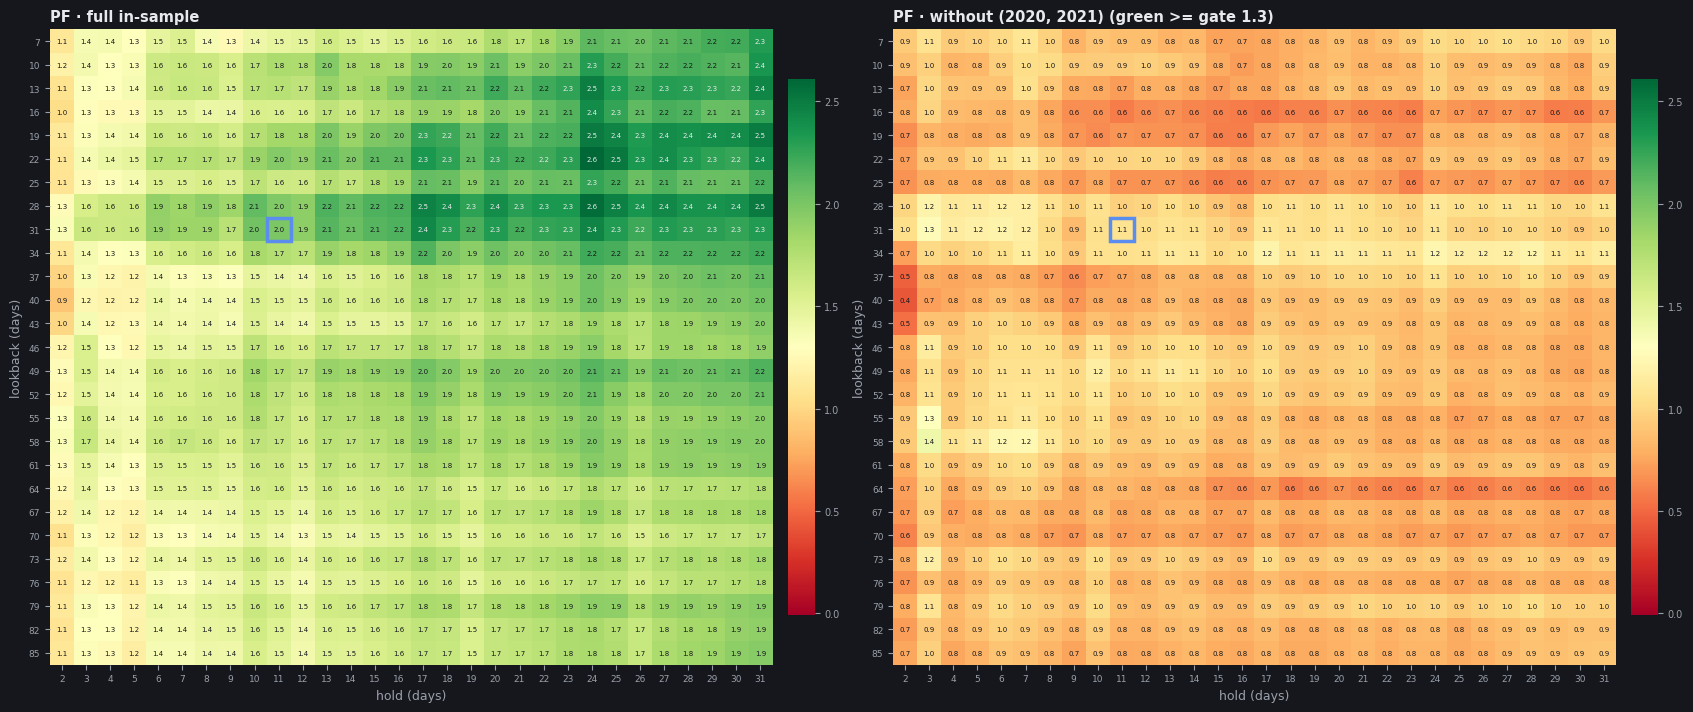


Checks registered:
   [PASS] plateau + anti-cliff gate, full in-sample (official)  ->  center PF 1.989, worst drop 13.7% vs 30%
   [PASS] configured point is not on the grid edge  ->  3x3 neighbourhood complete
   [PASS] majority of grid cells have mean net > 0  ->  807 of 810 cells
   [INFO] plateau gate without bull years (2020, 2021) (INFO, as in the original: not the gate; main fragility)  ->  center PF 1.066; 0% of cells PF >= 1.3


'INFO'

In [81]:
pl = plateau_check(pf_grid, n_grid, CHOSEN, pf_min=PF_MIN, n_min=N_MIN, max_drop_pct=MAX_DROP)
ia, ib = pf_grid.index.get_loc(LOOKBACK), pf_grid.columns.get_loc(HOLD)
sl = (slice(max(ia - 1, 0), ia + 2), slice(max(ib - 1, 0), ib + 2))
cells = pf_grid.stack()
rank = int((cells > pf_grid.loc[LOOKBACK, HOLD]).sum()) + 1

print("=" * 70); print(f"NEIGHBORHOOD OF THE CONFIGURED POINT lookback {LOOKBACK}, hold {HOLD}"); print("=" * 70)
print("Profit Factor:"); display(pf_grid.iloc[sl].round(3))
print("N trades:");      display(n_grid.iloc[sl].astype(int))
print(f"Center PF: {pl['center_pf']:.3f} | worst neighbor drop: {pl['worst_neighbor_drop_pct']:.1f}% (max {MAX_DROP}%)")
print(f"Plateau (all cells of the neighbourhood PF >= {PF_MIN} and N >= {N_MIN}): {'YES' if pl['plateau'] else 'NO'}")
print(f"Anti-cliff: {'PASS' if pl['anticliff'] else 'FAIL'} | Gate (plateau AND anti-cliff): {'PASS' if pl['passed'] else 'FAIL'}")
print(f"Cells with PF >= {PF_MIN}: {pl['pct_cells_pf_ok'] * 100:.0f}% of {len(cells)} | cells with mean net > 0: {int((mean_grid.stack() > 0).sum())} of {len(cells)}")
print(f"Configured point ranks #{rank} of {len(cells)} by PF | best cell: {pl['best_cell']} (PF {pl['best_pf']:.3f}) | configured on grid edge: {pl['edge_of_grid']}")
if pl["edge_of_grid"]:
    print(f"NOTE: the neighbourhood is truncated (hold axis = {HOLDS}); a PASS here is weaker evidence than on an interior point.")

# ---- Declared regime check (registered in section 9): same grid without the bull years fixed a priori in notebook 01 ----
def no_bull(t):
    return t[~pd.to_datetime(t["entry_time"]).dt.year.isin(BULL_YEARS)]
pf_b = mk(lambda L, H: profit_factor(no_bull(TR[(L, H)])["pnl"]) if len(no_bull(TR[(L, H)])) else 0.0)
n_b  = mk(lambda L, H: float(len(no_bull(TR[(L, H)]))))
pl_b = plateau_check(pf_b, n_b, CHOSEN, pf_min=PF_MIN, n_min=N_MIN, max_drop_pct=MAX_DROP)
print("\n" + "-" * 70)
print(f"REGIME CHECK · without {BULL_YEARS}: center PF {pl_b['center_pf']:.3f} | plateau {'YES' if pl_b['plateau'] else 'NO'} | "
      f"worst drop {pl_b['worst_neighbor_drop_pct']:.1f}% | gate {'PASS' if pl_b['passed'] else 'FAIL'} | cells PF >= {PF_MIN}: {pl_b['pct_cells_pf_ok'] * 100:.0f}%")
fig, axes = subplots(1, 2, figsize=(17, 7.2), grid=False)
span_b = max(float(pf_grid.max().max()) - PF_MIN, PF_MIN - float(pf_b.min().min()), 0.1)
heatmap(axes[0], pf_grid, "PF · full in-sample", vmin=PF_MIN - span_b, vmax=PF_MIN + span_b, fmt="{:.1f}", mark=CHOSEN, fs=5)
heatmap(axes[1], pf_b, f"PF · without {BULL_YEARS} (green >= gate {PF_MIN})", vmin=PF_MIN - span_b, vmax=PF_MIN + span_b, fmt="{:.1f}", mark=CHOSEN, fs=5)
plt.tight_layout(); plt.show()

print("\nChecks registered:")
C("4 Plateau", "plateau + anti-cliff gate, full in-sample (official)", pl["passed"], f"center PF {pl['center_pf']:.3f}, worst drop {pl['worst_neighbor_drop_pct']:.1f}% vs {MAX_DROP}%")
C("4 Plateau", "configured point is not on the grid edge", not bool(pl["edge_of_grid"]), "3x3 neighbourhood complete" if not pl["edge_of_grid"] else "neighbourhood truncated")
C("4 Plateau", "majority of grid cells have mean net > 0", bool((mean_grid.stack() > 0).mean() > 0.5), f"{int((mean_grid.stack() > 0).sum())} of {len(cells)} cells")
C("4 Regime", f"plateau gate without bull years {BULL_YEARS} (INFO, as in the original: not the gate; main fragility)", None, f"center PF {pl_b['center_pf']:.3f}; {pl_b['pct_cells_pf_ok'] * 100:.0f}% of cells PF >= {PF_MIN}")

## 5. DOSE-RESPONSE: DOES STRONGER MOMENTUM MEAN A BETTER NEXT WEEK?

At the configured lookback and hold, every signal week (both signs) is ranked by its past return and cut into quintiles. A real momentum effect shows a roughly monotonic climb of the next-week move. The naked-long / naked-short columns are the net result of holding that leg in **every** week of the bucket (same engine, spread and swap), which also shows what the signal avoids.

DOSE-RESPONSE · lookback 31 d, hold 11 d · in-sample · quintiles of the past return (all signal weeks)


,Weeks,Past return %,Next-week move % (gross),Up weeks %,Net if long %,Net if short %
q,,,,,,
Q1,50,-25.164,-0.113,44.000,-0.887,-0.201
Q2,49,-7.066,0.108,48.980,-0.626,-0.391
Q3,49,3.544,5.424,59.184,4.636,-5.735
Q4,49,20.231,1.169,59.184,0.394,-1.478
Q5,49,53.433,7.787,65.306,6.980,-8.128


Spearman (past return vs next-week move, weekly): rho = +0.111 (p = 0.082) | across the 5 quintile means: rho = +0.90 (descriptive, 5 points)
NOTE: with hold > 7 consecutive weeks overlap, so the weekly p-value is optimistic.


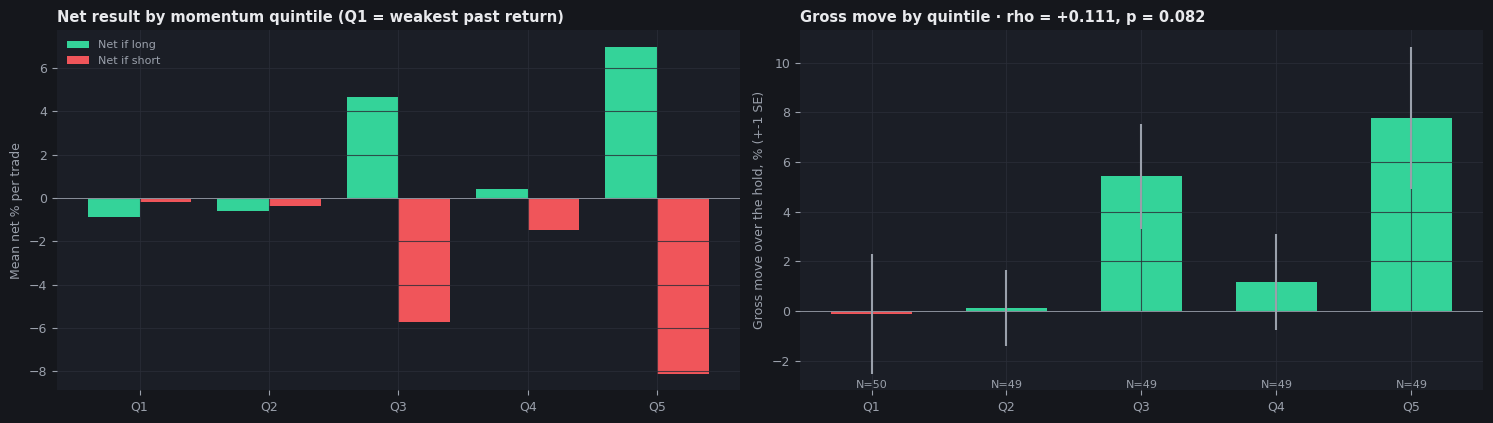

Checks registered:
   [INFO] Spearman p (INFO, as in the original: reported, not a gate; reference 0.05)  ->  rho +0.111, p 0.082 (optimistic: weekly rows overlap when hold > 7)
   [INFO] rho across the 5 quintile means (descriptive, 5 points)  ->  +0.90


'INFO'

In [82]:
def naked_trades(L, H, direction, d=None):
    """Same engine, same weeks, but the position is forced to one direction (sign of mom_ret overridden)."""
    d = (preps[L] if d is None else d).copy()
    d["mom_ret"] = np.abs(d["mom_ret"]) * (1.0 if direction == "long_only" else -1.0)
    return run_cell(L, H, d=d, direction=direction)

tl, ts = naked_trades(LOOKBACK, HOLD, "long_only"), naked_trades(LOOKBACK, HOLD, "short_only")
sig = run_cell(LOOKBACK, HOLD, direction="both")
sig["raw"] = sig["side"] * sig["gross_pct"]
sig["q"] = pd.qcut(sig["mom_ret"], 5, labels=[f"Q{i}" for i in range(1, 6)])
nl = tl.set_index("i_ent")["pnl"]; ns = ts.set_index("i_ent")["pnl"]
sig["net_long"], sig["net_short"] = sig["i_ent"].map(nl).to_numpy(), sig["i_ent"].map(ns).to_numpy()
dose = sig.groupby("q", observed=True).agg(n=("raw", "size"), mom=("mom_ret", "mean"), next_week=("raw", "mean"),
                                           up_share=("raw", lambda x: (x > 0).mean() * 100), net_if_long=("net_long", "mean"), net_if_short=("net_short", "mean"))
rho_d, p_d = stats.spearmanr(sig["mom_ret"], sig["raw"])
rho_q, _ = stats.spearmanr(np.arange(5), dose["next_week"])

print("=" * 70)
print(f"DOSE-RESPONSE · lookback {LOOKBACK} d, hold {HOLD} d · in-sample · quintiles of the past return (all signal weeks)")
print("=" * 70)
display(dose.rename(columns={"n": "Weeks", "mom": "Past return %", "next_week": "Next-week move % (gross)", "up_share": "Up weeks %",
                             "net_if_long": "Net if long %", "net_if_short": "Net if short %"}).round(3))
print(f"Spearman (past return vs next-week move, weekly): rho = {rho_d:+.3f} (p = {p_d:.3f}) | across the 5 quintile means: rho = {rho_q:+.2f} (descriptive, 5 points)")
if HOLD > 7:
    print("NOTE: with hold > 7 consecutive weeks overlap, so the weekly p-value is optimistic.")

se_q = sig.groupby("q", observed=True)["raw"].agg(lambda v: v.std(ddof=1) / np.sqrt(len(v))).reindex(dose.index)
x = np.arange(5)
fig, (ax1, ax2) = subplots(1, 2, figsize=(15, 4.3))
ax1.bar(x - 0.2, dose["net_if_long"], 0.4, color=GREEN, label="Net if long")
ax1.bar(x + 0.2, dose["net_if_short"], 0.4, color=RED, label="Net if short")
ax1.axhline(0, color=SUB, lw=0.6); ax1.set_xticks(x); ax1.set_xticklabels(dose.index, color=SUB)
ax1.set_ylabel("Mean net % per trade", color=SUB); legend(ax1)
set_title(ax1, "Net result by momentum quintile (Q1 = weakest past return)")
ax2.bar(x, dose["next_week"], 0.6, yerr=se_q, ecolor=SUB, color=[GREEN if v > 0 else RED for v in dose["next_week"]])
ax2.axhline(0, color=SUB, lw=0.6); ax2.set_xticks(x); ax2.set_xticklabels(dose.index, color=SUB)
for i, n_ in enumerate(dose["n"]):
    ax2.text(i, ax2.get_ylim()[0], f"N={int(n_)}", color=SUB, fontsize=8, ha="center", va="bottom")
ax2.set_ylabel("Gross move over the hold, % (+-1 SE)", color=SUB)
set_title(ax2, f"Gross move by quintile · rho = {rho_d:+.3f}, p = {p_d:.3f}")
plt.tight_layout(); plt.show()

print("Checks registered:")
C("5 Dose-response", f"Spearman p (INFO, as in the original: reported, not a gate; reference {P_DOSE_MAX})", None,
  f"rho {rho_d:+.3f}, p {p_d:.3f}" + (" (optimistic: weekly rows overlap when hold > 7)" if HOLD > 7 else ""))
C("5 Dose-response", "rho across the 5 quintile means (descriptive, 5 points)", None, f"{rho_q:+.2f}")

## 6. ENTRY-TIMING ROBUSTNESS

The signal is read at the close before the entry; the entry is Monday 00:00 server time. Here the **hour** (server clock) and then the **weekday** move, with the configured lookback / hold, next to the naked position at the same timing. If the edge lived only at one slot it would be a data artefact.

**How to read it:** passing means the effect does not depend on the Monday 00:00 slot. That is also what the ETH drift alone would produce (the naked long passes too), so this section is informational and is **not** counted as evidence for the signal.

ENTRY-HOUR SENSITIVITY (server clock) · in-sample · lookback 31, hold 11, long_only vs naked long


,Trades,PF,Mean net %,t,PF naked,Mean net % naked
Entry,,,,,,
Mon 00:00,142,1.989,3.968,2.505,1.448,2.087
Mon 01:00,145,1.881,3.664,2.341,1.384,1.838
Mon 02:00,146,1.873,3.671,2.367,1.365,1.766
Mon 03:00,145,1.757,3.350,2.151,1.346,1.692
Mon 04:00,146,1.811,3.508,2.298,1.376,1.806
Mon 06:00,143,1.902,3.692,2.515,1.381,1.787
Mon 08:00,137,1.742,3.158,2.157,1.348,1.648
Mon 12:00,138,1.992,4.056,2.595,1.397,1.834


ENTRY-WEEKDAY SENSITIVITY · in-sample


,Trades,PF,Mean net %,t,PF naked,Mean net % naked
Entry,,,,,,
Mon 00:00,142,1.989,3.968,2.505,1.448,2.087
Tue 00:00,142,1.903,3.816,2.426,1.385,1.822
Wed 00:00,142,1.904,3.885,2.320,1.484,2.277
Thu 00:00,143,1.590,2.558,1.673,1.422,1.905
Fri 00:00,145,1.480,2.104,1.516,1.461,2.020
Sat 00:00,138,1.636,2.867,1.765,1.520,2.226
Sun 00:00,141,1.718,3.173,1.958,1.485,2.140


Consistency check vs section 3 at the configured slot: PF 1.989 vs 1.989
Hours with PF >= 1.3: 100% | weekdays with PF >= 1.3: 100% | hours where the rule beats naked on mean net: 100%
Naked long (no signal) has PF >= 1.3 in 100% of the hours and 100% of the weekdays.
READING: passing this sweep only rules out a single-slot artefact. It is NOT evidence for the signal: a long ETH position at any slot rides the same drift.


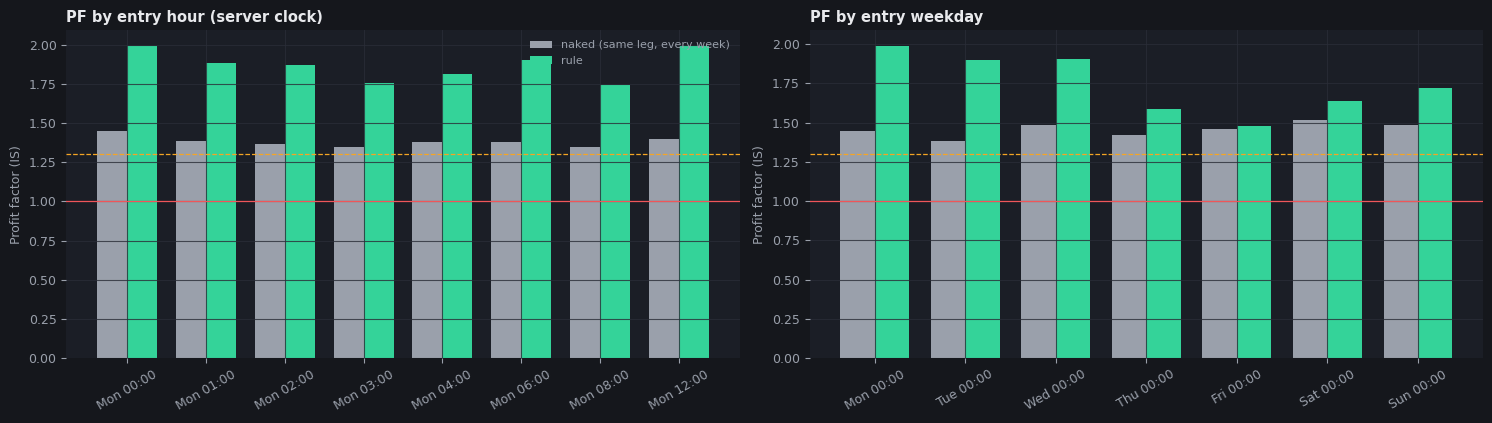

Checks registered (informational: timing does not discriminate the signal):
   [INFO] entry hours / weekdays with PF >= 1.3  ->  100% / 100%; naked long: 100% / 100%
   [INFO] rule beats the naked position on mean net, by hour  ->  100% of the hours


'INFO'

In [83]:
def timing_row(label, dow, hour):
    d = eng.prepare(df_raw, lookback_days=LOOKBACK, entry_dow=dow, entry_hour=hour)
    t = run_cell(LOOKBACK, HOLD, d=d, entry_dow=dow, entry_hour=hour)
    dn = d.copy(); dn["mom_ret"] = np.abs(dn["mom_ret"]) * (-1.0 if NAKED_DIR == "short_only" else 1.0)
    tn = run_cell(LOOKBACK, HOLD, d=dn, entry_dow=dow, entry_hour=hour, direction=NAKED_DIR)
    s, sn = summarize(t), summarize(tn)
    return {"Entry": label, "Trades": s["n"], "PF": s["pf"], "Mean net %": s["mean"], "t": s["t"], "PF naked": sn["pf"], "Mean net % naked": sn["mean"]}

HOURS = [0, 1, 2, 3, 4, 6, 8, 12]
DAYS = {0: "Mon", 1: "Tue", 2: "Wed", 3: "Thu", 4: "Fri", 5: "Sat", 6: "Sun"}
hour_tbl = pd.DataFrame([timing_row(f"{DAYS[ENTRY_DOW]} {h:02d}:00", ENTRY_DOW, h) for h in HOURS]).set_index("Entry")
day_tbl  = pd.DataFrame([timing_row(f"{DAYS[k]} {ENTRY_HOUR:02d}:00", k, ENTRY_HOUR) for k in DAYS]).set_index("Entry")
print("=" * 70); print(f"ENTRY-HOUR SENSITIVITY (server clock) · in-sample · lookback {LOOKBACK}, hold {HOLD}, {DIRECTION} vs naked {NAKED_DIR.split('_')[0]}"); print("=" * 70)
display(hour_tbl.round(3))
print("=" * 70); print("ENTRY-WEEKDAY SENSITIVITY · in-sample"); print("=" * 70)
display(day_tbl.round(3))
ref = summarize(TR[CHOSEN])
print(f"Consistency check vs section 3 at the configured slot: PF {hour_tbl.iloc[HOURS.index(ENTRY_HOUR), 1]:.3f} vs {ref['pf']:.3f}")
share_h = float((hour_tbl["PF"] >= PF_MIN).mean()); share_d = float((day_tbl["PF"] >= PF_MIN).mean())
beat_h  = float((hour_tbl["Mean net %"] > hour_tbl["Mean net % naked"]).mean())
print(f"Hours with PF >= {PF_MIN}: {share_h * 100:.0f}% | weekdays with PF >= {PF_MIN}: {share_d * 100:.0f}% | hours where the rule beats naked on mean net: {beat_h * 100:.0f}%")

share_hn = float((hour_tbl["PF naked"] >= PF_MIN).mean()); share_dn = float((day_tbl["PF naked"] >= PF_MIN).mean())
print(f"Naked {NAKED_DIR.split('_')[0]} (no signal) has PF >= {PF_MIN} in {share_hn * 100:.0f}% of the hours and {share_dn * 100:.0f}% of the weekdays.")
print("READING: passing this sweep only rules out a single-slot artefact. It is NOT evidence for the signal: a long ETH position at any slot rides the same drift.")

fig, (ax1, ax2) = subplots(1, 2, figsize=(15, 4.3))
for ax, tbl, ttl in ((ax1, hour_tbl, "PF by entry hour (server clock)"), (ax2, day_tbl, "PF by entry weekday")):
    xx, w = np.arange(len(tbl)), 0.38
    ax.bar(xx - w / 2, tbl["PF naked"].replace(np.inf, np.nan), w, color=SUB, label="naked (same leg, every week)")
    ax.bar(xx + w / 2, tbl["PF"].replace(np.inf, np.nan), w, color=GREEN, label="rule")
    ax.axhline(1.0, color=RED, lw=0.9); ax.axhline(PF_MIN, color=ORANGE, ls="--", lw=0.9)
    ax.set_xticks(xx); ax.set_xticklabels([str(i) for i in tbl.index], rotation=30, color=SUB)
    ax.set_ylabel("Profit factor (IS)", color=SUB); set_title(ax, ttl)
legend(ax1, "upper right")
plt.tight_layout(); plt.show()

print("Checks registered (informational: timing does not discriminate the signal):")
C("6 Timing", f"entry hours / weekdays with PF >= {PF_MIN}", None, f"{share_h * 100:.0f}% / {share_d * 100:.0f}%; naked long: {share_hn * 100:.0f}% / {share_dn * 100:.0f}%")
C("6 Timing", "rule beats the naked position on mean net, by hour", None, f"{beat_h * 100:.0f}% of the hours")

## 7. SIGNAL ABLATION BY YEAR (IN-SAMPLE)

What does the momentum signal add? **Naked** = the same leg held in every signal week (ETH drift). **Kept** = the weeks the rule trades. **Skipped** = the weeks the signal avoids, held anyway. Cells show `PF | mean net % | N`. The signal earns its place only if *kept* beats *naked*, and does so beyond a single year.

SIGNAL ABLATION · in-sample · net of spread and swap · PF | mean net % | N


,2019,2020,2021,2022,2023,All in-sample
Variant,,,,,,
Naked long (all signal weeks),0.76 | -1.502% | 40,3.43 | +7.211% | 52,2.05 | +5.237% | 52,0.63 | -2.611% | 51,1.49 | +1.165% | 51,1.45 | +2.087% | 246
Kept: rule traded (long_only),1.26 | +1.486% | 21,3.86 | +8.023% | 38,2.44 | +6.824% | 35,0.65 | -2.355% | 14,1.25 | +0.632% | 34,1.99 | +3.968% | 142
"Skipped weeks, same leg held anyway",0.29 | -4.806% | 19,2.46 | +5.009% | 14,1.35 | +1.970% | 17,0.63 | -2.708% | 37,2.03 | +2.231% | 17,0.91 | -0.480% | 104



Mean net % per trade by entry year, kept vs naked:


,kept,naked,excess
entry_time,,,
2019,1.486,-1.502,2.989
2020,8.023,7.211,0.812
2021,6.824,5.237,1.587
2022,-2.355,-2.611,0.256
2023,0.632,1.165,-0.533


Kept beats naked in 4 of 5 years | best year 2020: net t without it = 1.50 | net mean without (2020, 2021): +0.286% (naked -0.943%)


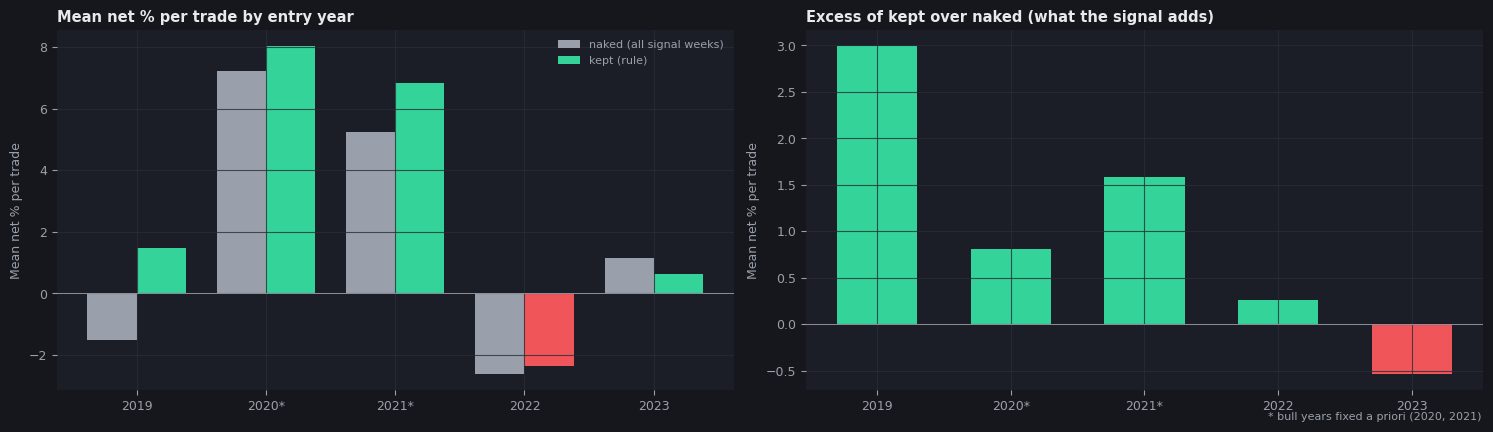

Checks registered:
   [INFO] t without the best year (2020) >= 1.5 (INFO: gate only when STRICT_YEARS)  ->  t = 1.496 (Newey-West)
   [PASS] kept beats naked beyond a single year (>= 2 years)  ->  4 of 5
   [INFO] net mean without (2020, 2021), kept vs naked (INFO)  ->  kept +0.286% vs naked -0.943%


'INFO'

In [84]:
t_naked = naked_trades(LOOKBACK, HOLD, NAKED_DIR)
t_kept = TR[CHOSEN]
kept_i = set(t_kept["i_ent"])
rows_def = [("Naked " + NAKED_DIR.split("_")[0] + " (all signal weeks)", t_naked), (f"Kept: rule traded ({DIRECTION})", t_kept)]
if DIRECTION != "both":
    rows_def.append(("Skipped weeks, same leg held anyway", t_naked[~t_naked["i_ent"].isin(kept_i)]))
else:
    rows_def += [("Long leg of the rule", t_kept[t_kept["side"] > 0]), ("Short leg of the rule", t_kept[t_kept["side"] < 0])]

yrs = sorted(pd.to_datetime(t_kept["entry_time"]).dt.year.unique())
fmt = lambda s: f"{s['pf']:.2f} | {s['mean']:+.3f}% | {s['n']}" if s["n"] else "n/a"
tab, per_year = [], {}
for name, t in rows_def:
    y = pd.to_datetime(t["entry_time"]).dt.year
    row = {"Variant": name}
    for yy in yrs:
        row[str(yy)] = fmt(summarize(t[y == yy]))
    row["All in-sample"] = fmt(summarize(t)); tab.append(row)
    per_year[name] = t.groupby(y)["pnl"].mean()
print("=" * 70); print(f"SIGNAL ABLATION · in-sample · net of spread and swap · PF | mean net % | N"); print("=" * 70)
display(pd.DataFrame(tab).set_index("Variant"))

k_name, n_name = rows_def[1][0], rows_def[0][0]
yy = pd.DataFrame({"kept": per_year[k_name], "naked": per_year[n_name]}).dropna()
yy["excess"] = yy["kept"] - yy["naked"]
print("\nMean net % per trade by entry year, kept vs naked:"); display(yy.round(3))
win_years = int((yy["excess"] > 0).sum())
by_year_t = t_kept.assign(year=pd.to_datetime(t_kept["entry_time"]).dt.year)
best_y = int(by_year_t.groupby("year")["pnl"].mean().idxmax())
rest = t_kept[~pd.to_datetime(t_kept["entry_time"]).dt.year.eq(best_y)]
lags_c = max(int(round(HOLD / 7)) - 1, 0)
print(f"Kept beats naked in {win_years} of {len(yy)} years | best year {best_y}: net t without it = {tstat_hac(rest['pnl'], lags_c):.2f} | "
      f"net mean without {BULL_YEARS}: {no_bull(t_kept)['pnl'].mean():+.3f}% (naked {no_bull(t_naked)['pnl'].mean():+.3f}%)")

t_nb = tstat_hac(rest["pnl"], lags_c)
fig, (ax1, ax2) = subplots(1, 2, figsize=(15, 4.3))
xx, w = np.arange(len(yy)), 0.38
xl = [f"{y}*" if y in BULL_YEARS else str(y) for y in yy.index]
ax1.bar(xx - w / 2, yy["naked"], w, color=SUB, label="naked (all signal weeks)")
ax1.bar(xx + w / 2, yy["kept"], w, color=[GREEN if v > 0 else RED for v in yy["kept"]], label="kept (rule)")
ax2.bar(xx, yy["excess"], 0.6, color=[GREEN if v > 0 else RED for v in yy["excess"]])
for ax, ttl in ((ax1, "Mean net % per trade by entry year"), (ax2, "Excess of kept over naked (what the signal adds)")):
    ax.axhline(0, color=SUB, lw=0.6); ax.set_xticks(xx); ax.set_xticklabels(xl, color=SUB)
    ax.set_ylabel("Mean net % per trade", color=SUB); set_title(ax, ttl)
legend(ax1, "upper right")
fig.text(0.99, 0.01, f"* bull years fixed a priori {BULL_YEARS}", color=SUB, fontsize=8, ha="right", va="bottom")
plt.tight_layout(); plt.show()

print("Checks registered:")
C("7 Ablation", f"t without the best year ({best_y}) >= {T_NO_BEST:g}" + ("" if STRICT_YEARS else " (INFO: gate only when STRICT_YEARS)"), (t_nb >= T_NO_BEST) if STRICT_YEARS else None, f"t = {t_nb:.3f} (Newey-West)")
C("7 Ablation", "kept beats naked beyond a single year (>= 2 years)", win_years >= 2, f"{win_years} of {len(yy)}")
C("7 Ablation", f"net mean without {BULL_YEARS}, kept vs naked (INFO)", None,
  f"kept {no_bull(t_kept)['pnl'].mean():+.3f}% vs naked {no_bull(t_naked)['pnl'].mean():+.3f}%")

## 8. EVIDENCE BAR (MULTIPLE TESTING)

The in-sample t is compared with a one-sided Bonferroni threshold for `k` hypotheses. `k` should be the number of variants and searches that were really looked at, declared in the YAML as `evidence_thresholds.hypotheses_tested`. The configured t is already Newey-West; the plain t is shown only to see how much the overlap inflates it.

EVIDENCE BAR · BONFERRONI (one-sided, alpha = 0.05)
Configured cell in-sample: N 142 | t Newey-West 2.51 | plain t 2.85 (overstated: consecutive holds overlap when hold > 7)


,what,threshold,IS t (NW),passes
k,,,,
2,declared (fallback k = 2 (v1 + long only): dec...,1.960,2.505,True
810,"grid searched (upper bound, not 'the' k)",3.839,2.505,False


The IS t clears the Bonferroni bar up to k ~ 8 hypotheses. The grid had 810 cells: the honest k lies somewhere in between and should be declared.


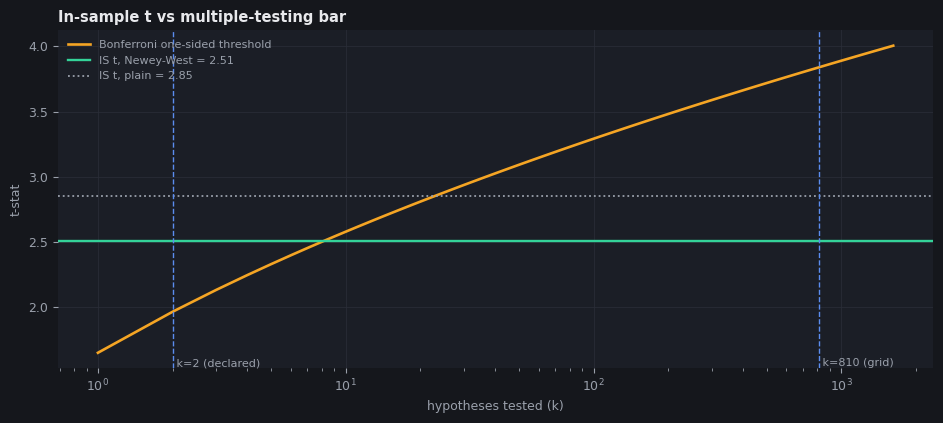

Checks registered:
   [PASS] IS t (Newey-West) >= Bonferroni threshold at the declared k = 2  ->  t 2.51 vs 1.96 (fallback k = 2 (v1 + long only): declare evidence_thresholds.hypotheses_tested in the YAML)
   [INFO] IS t (Newey-West) vs Bonferroni threshold at k = 810 grid cells (reference, not a gate)  ->  t 2.51 vs 3.84; clears up to k ~ 8


'INFO'

In [85]:
cfg_ev = cfg.get("evidence_thresholds") or {}
K_HYP = int(cfg_ev.get("hypotheses_tested", K_HYP_FALLBACK))
K_SRC = "YAML" if "hypotheses_tested" in cfg_ev else f"fallback k = {K_HYP_FALLBACK} (v1 + long only): declare evidence_thresholds.hypotheses_tested in the YAML"
K_GRID = len(LOOKBACKS) * len(HOLDS)
s_cfg = summarize(TR[CHOSEN])                         # t already Newey-West (lag = round(hold/7) - 1)
t_plain = tstat(TR[CHOSEN]["pnl"])                    # same trades, no overlap adjustment
thr_decl, thr_grid = hypothesis_threshold(K_HYP), hypothesis_threshold(K_GRID)
k_break = (0.05 / float(stats.norm.sf(s_cfg["t"]))) if s_cfg["t"] > 0 else 0.0

print("=" * 70); print("EVIDENCE BAR · BONFERRONI (one-sided, alpha = 0.05)"); print("=" * 70)
print(f"Configured cell in-sample: N {s_cfg['n']} | t Newey-West {s_cfg['t']:.2f} | plain t {t_plain:.2f} (overstated: consecutive holds overlap when hold > 7)")
ev = pd.DataFrame([{"k": K_HYP, "what": f"declared ({K_SRC})", "threshold": thr_decl, "IS t (NW)": s_cfg["t"], "passes": bool(s_cfg["t"] >= thr_decl)},
                   {"k": K_GRID, "what": "grid searched (upper bound, not 'the' k)", "threshold": thr_grid, "IS t (NW)": s_cfg["t"], "passes": bool(s_cfg["t"] >= thr_grid)}]).set_index("k")
display(ev.round(3))
print(f"The IS t clears the Bonferroni bar up to k ~ {k_break:,.0f} hypotheses. The grid had {K_GRID} cells: the honest k lies somewhere in between and should be declared.")

ks = np.unique(np.round(np.logspace(0, np.log10(max(K_GRID * 2, 10)), 80)).astype(int))
fig, ax = subplots(1, 1, figsize=(9.5, 4.3))
ax.plot(ks, [hypothesis_threshold(k) for k in ks], color=ORANGE, lw=1.9, label="Bonferroni one-sided threshold")
ax.axhline(s_cfg["t"], color=GREEN, lw=1.7, label=f"IS t, Newey-West = {s_cfg['t']:.2f}")
ax.axhline(t_plain, color=SUB, ls=":", lw=1.3, label=f"IS t, plain = {t_plain:.2f}")
ax.set_xscale("log")
for k_, nm in ((K_HYP, "declared"), (K_GRID, "grid")):
    ax.axvline(k_, color=BLUE, ls="--", lw=1.0)
    ax.text(k_, ax.get_ylim()[0], f" k={k_} ({nm})", color=SUB, fontsize=8, va="bottom")
ax.set_xlabel("hypotheses tested (k)", color=SUB); ax.set_ylabel("t-stat", color=SUB)
legend(ax, "upper left"); set_title(ax, "In-sample t vs multiple-testing bar")
plt.tight_layout(); plt.show()

print("Checks registered:")
C("8 Evidence", f"IS t (Newey-West) >= Bonferroni threshold at the declared k = {K_HYP}", s_cfg["t"] >= thr_decl, f"t {s_cfg['t']:.2f} vs {thr_decl:.2f} ({K_SRC})")
C("8 Evidence", f"IS t (Newey-West) vs Bonferroni threshold at k = {K_GRID} grid cells (reference, not a gate)", None, f"t {s_cfg['t']:.2f} vs {thr_grid:.2f}; clears up to k ~ {k_break:,.0f}")

## 9. CHECKS REGISTRY, VERDICT & NEXT STEPS

In [86]:
chk = C.frame()
colors = {"PASS": "color:#34d399", "FAIL": "color:#f0555a", "INFO": "color:#f5a524"}
try:
    sty = chk.style
    display((sty.map if hasattr(sty, "map") else sty.applymap)(lambda s: colors.get(s, ""), subset=["status"]))
except ImportError:                      # Styler needs jinja2
    display(chk)
cnt = C.counts()
print(f"PASS {cnt['PASS']} | FAIL {cnt['FAIL']} | INFO {cnt['INFO']}")

,section,name,status,detail
0,3.5 Stress,configured cell is gold in Base (plateau + t >= 2 + inside hard limit + N >= 100),PASS,80 gold cells in Base
1,3.5 Stress,configured cell is gold in all 4 cost scenarios,PASS,4/4 scenarios
2,3.5 Stress,PF at spread x2 + swap x2 >= 1.3,PASS,"PF 1.736, mean net +3.181%"
3,3.6 Sizing,MaxDD at the robot sizing is inside the hard limit (Base),PASS,-6.6% vs -9%
4,3.6 Sizing,capital >= minimum for the minimum lot at the robot fraction,FAIL,"3,000 vs 4,467"
5,4 Plateau,"plateau + anti-cliff gate, full in-sample (official)",PASS,"center PF 1.989, worst drop 13.7% vs 30%"
6,4 Plateau,configured point is not on the grid edge,PASS,3x3 neighbourhood complete
7,4 Plateau,majority of grid cells have mean net > 0,PASS,807 of 810 cells
8,4 Regime,"plateau gate without bull years (2020, 2021) (INFO, as in the original: not the gate; main fragility)",INFO,center PF 1.066; 0% of cells PF >= 1.3
9,5 Dose-response,"Spearman p (INFO, as in the original: reported, not a gate; reference 0.05)",INFO,"rho +0.111, p 0.082 (optimistic: weekly rows overlap when hold > 7)"


PASS 9 | FAIL 1 | INFO 8


In [87]:
ready  = bool(pl["passed"]) and CFG_GOLD["Base"]   # plateau + t>=2 + hard limit en Base
robust = CFG_GOLD_ALL                               # lo mismo en los 4 escenarios de costos
base, x2 = stress.loc["Base"], stress.loc["Spread x2 + Swap x2"]
swap_ok = bool(x2["PF"] >= PF_MIN)
weak = [c for c in C.items if c["status"] == "FAIL"]
weak_txt = "\n".join(f"   - [{c['section']}] {c['name']}: {c['detail']}" for c in weak) or "   (none)"
ready_all = len(weak) == 0
print("=" * 80); print("9. SUMMARY OF IN-SAMPLE PARAMETER STABILITY"); print("=" * 80)
print(f"""
Key Findings:

1. Plateau gate (full in-sample, official): {'PASS' if pl['passed'] else 'FAIL'} - center PF {pl['center_pf']:.3f}, worst neighbor drop {pl['worst_neighbor_drop_pct']:.1f}%,
   plateau {'yes' if pl['plateau'] else 'no'}; {pl['pct_cells_pf_ok'] * 100:.0f}% of {len(cells)} cells have PF >= {PF_MIN}; configured point ranks #{rank}; on grid edge: {pl['edge_of_grid']}.
   Regime check without {BULL_YEARS} (declared check, not a footnote): {'PASS' if pl_b['passed'] else 'FAIL'} (center PF {pl_b['center_pf']:.3f}, {pl_b['pct_cells_pf_ok'] * 100:.0f}% of cells PF >= {PF_MIN}).

2. Stress: spread x2 + swap x2 -> PF {x2['PF']:.3f}, mean net {x2['Mean net %']:+.3f}% (base {base['PF']:.3f} / {base['Mean net %']:+.3f}%); plateau {x2['Plateau (configured)']}; {'PF stays above' if swap_ok else 'PF falls below'} the gate.

3. Dose-response: Spearman rho {rho_d:+.3f} (p = {p_d:.3f}) between past return and next-week move; quintile means rho {rho_q:+.2f}. Reference p <= {P_DOSE_MAX}: {'met' if p_d <= P_DOSE_MAX else 'not met'} (not a gate).

4. Timing (informational, NOT evidence for the signal): {share_h * 100:.0f}% of entry hours and {share_d * 100:.0f}% of weekdays keep PF >= {PF_MIN}, but the naked long does too in {share_hn * 100:.0f}% / {share_dn * 100:.0f}%.
   The effect does not depend on Monday 00:00, which is also what the ETH drift alone would produce.

5. Ablation: kept beats naked in {win_years} of {len(yy)} years; net t without the best year ({best_y}) = {t_nb:.2f} (reference {T_NO_BEST:g}; gate only with STRICT_YEARS).

6. Evidence bar: IS t (Newey-West) {s_cfg['t']:.2f} vs Bonferroni one-sided threshold {thr_decl:.2f} for k = {K_HYP} ({K_SRC});
   it clears the bar up to k ~ {k_break:,.0f}; at k = {K_GRID} (grid cells) the bar is {thr_grid:.2f}.

7. Known weaknesses carried to 03 (every FAIL of the registry; PASS {cnt['PASS']} | FAIL {cnt['FAIL']} | INFO {cnt['INFO']}):
{weak_txt}

8. Next Step: {('proceed to 03 with the frozen parameters' + ('' if robust else ' (passes Base only: fails t>=2 / hard limit under cost stress; carry as a known weakness)')) if ready else 'the official gate failed in-sample. Do NOT re-tune lookback / hold on this result: document it and carry it to notebook 03 as a known weakness.'}
""")

9. SUMMARY OF IN-SAMPLE PARAMETER STABILITY

Key Findings:

1. Plateau gate (full in-sample, official): PASS - center PF 1.989, worst neighbor drop 13.7%,
   plateau yes; 93% of 810 cells have PF >= 1.3; configured point ranks #170; on grid edge: False.
   Regime check without (2020, 2021) (declared check, not a footnote): FAIL (center PF 1.066, 0% of cells PF >= 1.3).

2. Stress: spread x2 + swap x2 -> PF 1.736, mean net +3.181% (base 1.989 / +3.968%); plateau PASS; PF stays above the gate.

3. Dose-response: Spearman rho +0.111 (p = 0.082) between past return and next-week move; quintile means rho +0.90. Reference p <= 0.05: not met (not a gate).

4. Timing (informational, NOT evidence for the signal): 100% of entry hours and 100% of weekdays keep PF >= 1.3, but the naked long does too in 100% / 100%.
   The effect does not depend on Monday 00:00, which is also what the ETH drift alone would produce.

5. Ablation: kept beats naked in 4 of 5 years; net t without the best year (2020) =

## 10. SAVE THE RESULTS FOR THE VARIANT

In [88]:
save_json(cfg, "02_plateau.json", {
    "variant": cfg["id"], "params": cfg["params"], "oos_start": str(OOS_START.date()), "common_start": str(COMMON_START.date()),
    "plateau": {k: (v if isinstance(v, (bool, int, float, str)) or v is None else str(v)) for k, v in pl.items()},
    "plateau_without_bull_years": {"years": list(BULL_YEARS), "passed": bool(pl_b["passed"]), "center_pf": float(pl_b["center_pf"])},
    "grids": {"pf": pf_grid.round(4).to_dict(), "n": n_grid.to_dict(), "mean_net": mean_grid.round(4).to_dict(), "t_adj": t_grid.round(3).to_dict(), "max_dd_pct": dd_grid.round(2).to_dict()},
    "stress": stress.round(4).reset_index().to_dict(orient="records"),
    "dose_response": {"spearman_rho": float(rho_d), "p": float(p_d), "table": dose.round(4).reset_index().to_dict(orient="records")},
    "timing": {"hours": hour_tbl.round(4).reset_index().to_dict(orient="records"), "weekdays": day_tbl.round(4).reset_index().to_dict(orient="records")},
    "baseline_is": {"n": int(s_cfg["n"]), "pf": float(s_cfg["pf"]), "mean_net_pct": float(s_cfg["mean"]), "t_hac": float(s_cfg["t"]), "t_plain": float(t_plain), "win_pct": float(s_cfg["win"])},
    "evidence": {"k_declared": int(K_HYP), "k_source": K_SRC, "bonferroni_threshold_declared": float(thr_decl), "k_grid": int(K_GRID),
                 "bonferroni_threshold_grid": float(thr_grid), "k_break_even": float(k_break)},
    "ablation": {"kept_beats_naked_years": win_years, "years": len(yy), "best_year": best_y, "t_without_best_year": float(t_nb)},
    "ready_for_03": ready,                       # unchanged meaning: plateau gate + gold in Base
    "ready_all_checks": bool(ready_all),         # new: no FAIL left in the registry
    "checks": C.items, "counts": cnt, "inherited_weaknesses": weak,
})

Saved: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/ETHUSD_Weekly_Momentum/runs/v2_ethusd_long/02_plateau.json


PosixPath('/Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/ETHUSD_Weekly_Momentum/runs/v2_ethusd_long/02_plateau.json')